In [6]:
#%pip install fiona
#%pip install contextily
#%pip install plotly

In [1]:
import pandas as pd  
import matplotlib.pyplot as plt  
import os
import geopandas as gpd  
import numpy as np  
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io.shapereader import Reader
import matplotlib.patheffects as pe
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from matplotlib import gridspec
import matplotlib as mpl
from matplotlib.patches import Patch
from matplotlib.colors import rgb_to_hsv
from matplotlib import colors as mcolors  
from matplotlib.ticker import MaxNLocator

os.chdir('C:\\Users\\hamod4691\\Code\\arctic-benthic-biodiversity')

In [ ]:
# To preview output, open terminal and paste: 
# quarto preview Manuscript/data_paper_manuscript.ipynb --no-browser

In [ ]:
# To render output to pdf and word, open terminal and paste: 
# quarto render Manuscript/data_paper_manuscript.ipynb --to pdf --to docx

In [69]:
# Count summary values and station count using the manuscript station definition
all_merged = pd.read_parquet("Final/merged_all_final.parquet")

records = len(all_merged)
taxa = all_merged['aphiaID'].nunique()
datasets = all_merged['datasetKey'].nunique()
start_year = all_merged['year'].min()
end_year = all_merged['year'].max()
species_taxa = all_merged.loc[
    all_merged['taxonRank'].astype('string').str.strip().eq('Species'),
    'acceptedAphiaID'
].nunique()
gear_percentage = (all_merged['gear'].notna().sum() / records) * 100
biomass_percentage = (all_merged['biomass'].notna().sum() / records) * 100

# Station definition: datasetKey + rounded lat/lon (5 decimals) + rounded year; keep missing year
station_cols_required = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart']
station_key = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart', 'year', 'startDayOfYear']

stations_df = all_merged[station_key].copy()
stations_df['decimalLatitudeStart'] = pd.to_numeric(stations_df['decimalLatitudeStart'], errors='coerce').round(5)
stations_df['decimalLongitudeStart'] = pd.to_numeric(stations_df['decimalLongitudeStart'], errors='coerce').round(5)
stations_df['year'] = pd.to_numeric(stations_df['year'], errors='coerce').round().astype('Int64')
stations_df['startDayOfYear'] = pd.to_numeric(stations_df['startDayOfYear'], errors='coerce').round().astype('Int64')
stations_df = stations_df.dropna(subset=station_cols_required)

stations = stations_df.drop_duplicates(station_key).shape[0]


*Abstract*

In [4]:
display(Markdown(
    f"As the Arctic Ocean undergoes rapid environmental change and is subjected to increasing anthropogenic pressures, there is a growing need for comprehensive baseline data on its biodiversity. Although sampling efforts have been considerable over "
    f"the past decades, the existing biodiversity records are often fragmented and scattered across multiple databases. We present BENTH-MARC, an open pan-Arctic database with BENTHos in the Marine ARCtic. BENTH-MARC contains "
    f"{records:,.0f} georeferenced zoobenthic taxon records of {species_taxa:,.0f} species and {taxa - species_taxa:,.0f} taxa at other taxonomic levels from {datasets} datasets and {stations:,.0f} stations. Data span across the "
    f"entire pan-Arctic realm and integrate regional and global biodiversity databases as well as previously unpublished datasets. "
    f"The records in BENTH-MARC come from two and a half centuries of sampling, from {start_year:.0f}-{end_year:.0f}, and are based on morphological identification. "
    f"By providing harmonized and accessible data, BENTH-MARC can support the assessment of biological consequences of ongoing environmental change, aid in the identification of biodiversity hotspots and evaluation of conservation targets. "
    f"The database can also be used to guide future sampling efforts."
))

As the Arctic Ocean undergoes rapid environmental change and is subjected to increasing anthropogenic pressures, there is a growing need for comprehensive baseline data on its biodiversity. Although sampling efforts have been considerable over the past decades, the existing biodiversity records are often fragmented and scattered across multiple databases. We present BENTH-MARC, an open pan-Arctic database with BENTHos in the Marine ARCtic. BENTH-MARC contains 3,760,265 georeferenced zoobenthic taxon records of 8,442 species and 3,450 taxa at other taxonomic levels from 826 datasets and 223,349 stations. Data span across the entire pan-Arctic realm and integrate regional and global biodiversity databases as well as previously unpublished datasets. The records in BENTH-MARC come from two and a half centuries of sampling, from 1773-2026, and are based on morphological identification. By providing harmonized and accessible data, BENTH-MARC can support the assessment of biological consequences of ongoing environmental change, aid in the identification of biodiversity hotspots and evaluation of conservation targets. The database can also be used to guide future sampling efforts.

# Background

The Arctic Ocean is experiencing rapid environmental changes and an increase in anthropogenic pressures [@overland2019; @bidgood2024], which is in part linked to better accessibility as the sea ice withdraws [@pame2025]. The demand on Arctic resources is expected to increase in the future, with growing interests in, among others, deep-sea mining, oil and gas extraction, shipping and tourism in the region [@bidgood2024]. Currently, there are knowledge gaps on how large-scale biodiversity patterns will respond to these rapid environmental changes and elevated anthropogenic pressures [@brandt2023]. Sampling efforts in the Arctic Ocean have been considerable over the past decades [@ramirezllodra2024], and data accessibility has increased due to improved storage options and the growing prevalence of mandatory data publication [@michner2015]. Nevertheless, existing biodiversity records are often insufficient, fragmented, and scattered across multiple databases [@caff2017]. This creates considerable uncertainties and poses challenges for the sustainable management of the Arctic Ocean.

Benthic communities play a vital role in Arctic marine food webs, nutrient recycling, and the carbon cycle [@kedra2015], while also harboring the majority of marine biodiversity [@sirenko2001]. Furthermore, benthic organisms are widely regarded as key indicators of ecosystem health due to the strong coupling between environmental drivers and species composition and distribution patterns [@kraan2010; @kraan2015], as well as their comparatively long lifespans. As a result, studies investigating the impacts of environmentally hazardous activities, such as oil and gas extraction [@mauffrey2021; @chen2024] or infrastructure development [@leng2024], often rely on benthic communities in impact assessments. Understanding the current baseline of benthic biodiversity is therefore critical — not only for identifying present biodiversity hotspots but also for predicting the future state of the Arctic Ocean and for supporting sustainable development of environmentally hazardous activities. However, sampling zoobenthos in the Arctic Ocean presents significant challenges, including high costs, logistical difficulties, and limited accessibility. These challenges are particularly pronounced in deep-water areas, where research efforts remain scarce. Most studies to date have concentrated on sea ice, surface waters, and the water column, leaving substantial gaps in our understanding of deep benthic environments [@bluhm2011; @ramirezllodra2024]. To ensure that future sampling efforts target the areas of greatest need, it is essential to create an overview of the availability, structure, and coverage of existing data and metadata. Additionally, facilitating reuse of already existing data helps maximize the value of each sampling campaign. 

Previous large-scale compilations of Arctic benthic biodiversity include the works of Bluhm *et al.* [-@bluhm2011] and Ramirez Llodra *et al.* [-@ramirezllodra2024] on the Arctic basins, a taxon compilation by Sirenko *et al.* [-@sirenko2001] on the Russian Arctic Seas, an inventory of Arctic shelf seas by Piepenburg *et al.* [-@piepenburg2011], and a pan-Arctic overview of both shelves and basins by Piepenburg *et al.* [-@piepenburg2024]. 

In [70]:
display(Markdown(
    f"In a time of global change and competing sea-use interests, large-scale analyses at high taxonomic resolution are key for informing effective science-based decision-making. Such analyses can "
    f"be facilitated and improved by access to harmonized biodiversity and biomass data. Here, we present BENTH-MARC, an open pan-Arctic database with a focus on BENTHos in the Marine ARCtic. BENTH-MARC "
    f"includes {records:,.0f} zoobenthic records from the Global Biodiversity Information Facility (GBIF) [@gbif2026], Ocean Biodiversity Information System (OBIS) [@obis2026], CRITTERBASE  [@teschke2022], Observatoire "
    f"Global du Saint-Laurent (OGSL) [@ogsl2026] and previously unpublished datasets from Aarhus University. Each record represents an observation of a certain taxon at a specific location and time. This means that for example 200 individuals of the "
    f"same taxon, location and date count as a single record. The records span over the Arctic Large Marine Ecosystems [@pame2013] "
    f"and date back to as early as {start_year:.0f}. The records have been cleaned and harmonized and are now available for download in different formats. By providing harmonized and accessible data, "
    f"BENTH-MARC can support the assessment of biological consequences of ongoing environmental change and can be used to guide future sampling efforts. "
))

In a time of global change and competing sea-use interests, large-scale analyses at high taxonomic resolution are key for informing effective science-based decision-making. Such analyses can be facilitated and improved by access to harmonized biodiversity and biomass data. Here, we present BENTH-MARC, an open pan-Arctic database with a focus on BENTHos in the Marine ARCtic. BENTH-MARC includes 3,760,265 zoobenthic records from the Global Biodiversity Information Facility (GBIF) [@gbif2026], Ocean Biodiversity Information System (OBIS) [@obis2026], CRITTERBASE  [@teschke2022], Observatoire Global du Saint-Laurent (OGSL) [@ogsl2026] and previously unpublished datasets from Aarhus University. Each record represents an observation of a certain taxon at a specific location and time. This means that for example 200 individuals of the same taxon, location and date count as a single record. The records span over the Arctic Large Marine Ecosystems [@pame2013] and date back to as early as 1773. The records have been cleaned and harmonized and are now available for download in different formats. By providing harmonized and accessible data, BENTH-MARC can support the assessment of biological consequences of ongoing environmental change and can be used to guide future sampling efforts. 

::: {.content-hidden when-format="pdf"}
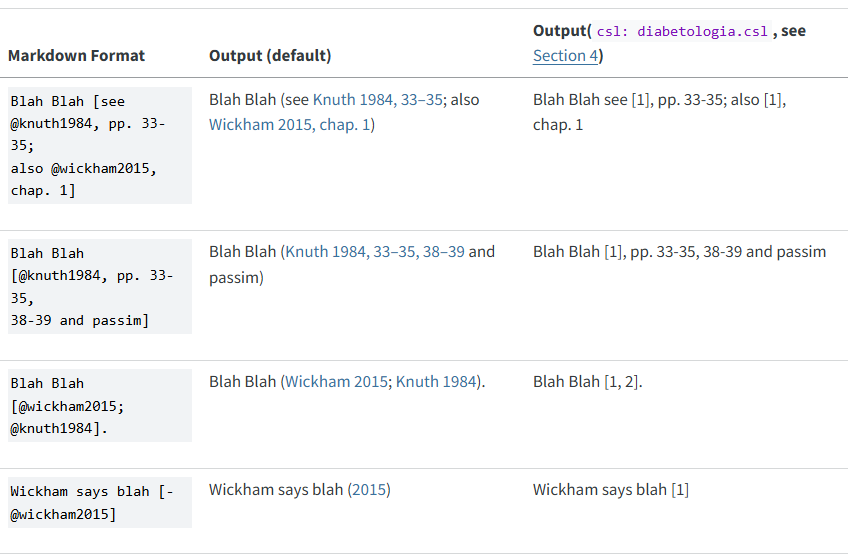
:::

# Methods
## Definition of the study area
The main study area consists of 18 Arctic Large Marine Ecosystems (LMEs), which are regions of ocean space of 200,000 km^2^ or greater that have unifying qualities in terms of productivity, bathymetry, hydrography and trophically linked populations [@pamend]. The Arctic LMEs were originally developed by the Arctic Council working group Protection of the Arctic Marine Environment (PAME) in 2006 and updated with revised boundaries in 2013 [@pame2013]. Using ecosystem-based units supports the application of an ecosystem approach to management, which has been promoted within the EU Marine Strategy Framework Directive and OSPAR contexts [@pamend]. @fig-map_stations provides an overview of all sampling stations as well as the spatial extent of the Arctic Large Marine Ecosystems.


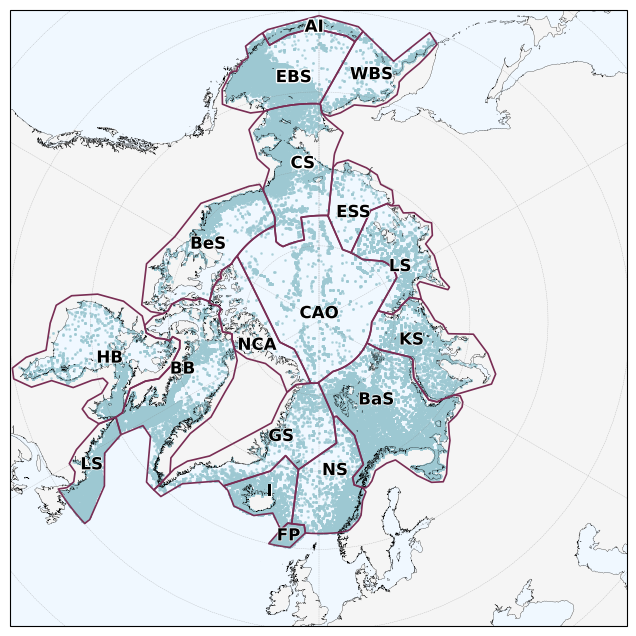

In [5]:
#| fig-pos: "H"
#| label: fig-map_stations
#| fig-cap: "Spatial distribution of sampling stations in the BENTH-MARC database. The Arctic Large Marine Ecosystems (purple lines) define the main study area. The Large Marine Ecosystems are Labrador Sea (LS), Hudson Bay (HB), Baffin Bay (BB), Beaufort Sea (BeS), Chukchi Sea (CS), West Bering Sea (WBS), East Bering Sea (EBS), Aleutian Islands (AI), East Siberian Sea (ESS), Laptev Sea (LS), Kara Sea (KS), Barents Sea (BaS), Norwegian Sea (NS), Iceland (I), Faroe Plateau (FP), Greenland Sea (GS), North Canadian Archipelago (NCA) and Central Arctic Ocean (CAO). "

# Ensure shapefile can be read even if .shx is missing
os.environ['SHAPE_RESTORE_SHX'] = 'YES'

# Load the data from device_water.xlsx
FILEPATH = 'Final/all_stations.parquet'
df_station = pd.read_parquet(FILEPATH)

# Use LatStart and LonStart for coordinates
lat = df_station['decimalLatitudeStart'].copy()
lon = df_station['decimalLongitudeStart'].copy()

# Create coordinates dataframe
coords = pd.DataFrame({
    'lat': pd.to_numeric(lat, errors='coerce'),
    'lon': pd.to_numeric(lon, errors='coerce')
})
coords = coords.dropna()

# Filter to plausible lat/lon ranges
coords = coords[(coords['lat'] >= -90) & (coords['lat'] <= 90) &
                (coords['lon'] >= -180) & (coords['lon'] <= 180)]


# Create the plot with smaller figure size
plt.figure(figsize=(8, 8))
proj = ccrs.NorthPolarStereo()
ax = plt.axes(projection=proj)
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.coastlines(resolution='10m', linewidth=0.2, color='black')
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')

# Add shapefile lines (EPSG:4326, same as stations)
shape_reader = Reader('LME_boundaries_2014/lme_2013_wgs.shp')
line_feature = cfeature.ShapelyFeature(
    list(shape_reader.geometries()),
    ccrs.PlateCarree(),
    edgecolor='#792D54',
    facecolor='none'
)
ax.add_feature(line_feature, linewidth=1.2)

# Read the shapefile with attributes so we can access names
gdf_lme = gpd.read_file('LME_boundaries_2014/lme_2013_wgs.shp')

# Ensure coordinates for labeling are in EPSG:4326 (PlateCarree)
gdf_lme_pc = gdf_lme.to_crs(epsg=4326)

# Step 1: Reproject to a projected CRS (e.g., EPSG:3395 for World Mercator)
gdf_lme_projected = gdf_lme.to_crs(epsg=3395)
# Step 2: Calculate centroids in the projected CRS
gdf_lme_projected['centroid'] = gdf_lme_projected.geometry.centroid
# Step 3: Reproject centroids back to the original geographic CRS (EPSG:4326)
gdf_lme_pc['centroid'] = gdf_lme_projected['centroid'].to_crs(epsg=4326)
# Step 4: Extract longitude and latitude for labeling
gdf_lme_pc['lon'] = gdf_lme_pc['centroid'].x  # Extract longitude
gdf_lme_pc['lat'] = gdf_lme_pc['centroid'].y  # Extract latitude


# Step 5: Add labels using the LME field
for _, row in gdf_lme_pc.iterrows():
    if row['LME'] in ['Central Arctic LME', 'Chukchi Sea LME', 'East Bering Sea LME', 'Alutian Islands LME']:
        # Skip these labels in the main loop
        continue
# Handle specific cases for Barents Sea and Beaufort Sea
    if row['LME'] == 'Barents Sea LME':
        short_label = 'BaS'  # Unique abbreviation for Barents Sea
    elif row['LME'] == 'Beaufort Sea LME':
        short_label = 'BeS'  # Unique abbreviation for Beaufort Sea
    else:
        words = row['LME'].split()  # Split the name into words
        short_label = ''.join([word[0] for word in words[:-1]])  # Take the first letter of each word except the last one
    # Add the label to the map
    ax.text(
        row['lon'],
        row['lat'],
        short_label,  # Use the shortened label
        transform=ccrs.PlateCarree(),
        fontsize=12,
        fontweight='bold',  # Make the text bold
        color='black',
        ha='center',
        va='center',
        path_effects=[pe.withStroke(linewidth=1, foreground='white')]
    )

# Step 7: Manual adjustment for problematic labels
for _, row in gdf_lme_pc.iterrows():
    if row['LME'] == 'Central Arctic LME':
        ax.text(
            -179, 89,  # Replace with correct longitude and latitude
            'CAO',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=1, foreground='white')]
        )
    elif row['LME'] == 'Chukchi Sea LME':
        ax.text(
            -174, 69,  # Replace with correct longitude and latitude
            'CS',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )
    elif row['LME'] == 'East Bering Sea LME':
        ax.text(
            -174, 58,  # Replace with correct longitude and latitude
            'EBS',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )
    elif row['LME'] == 'Alutian Islands LME':
        ax.text(
            -179, 52,  # Replace with correct longitude and latitude
            'AI',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )

# Plot the station points
ax.scatter(coords['lon'].values, coords['lat'].values,
           s=1, color='#9DC8D2', alpha=0.6, transform=ccrs.PlateCarree(), label='All stations')


plt.savefig("Figures/map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## Data sources

BENTH-MARC includes publicly available, and previously unpublished, georeferenced and morphologically identified metazoan datasets of meio-, macro- and megabenthos in the Arctic LMEs (@fig-map_stations). Only invertebrates were included, more specifically from the following phyla: Annelida, Mollusca, Arthropoda, Echinodermata, Cnidaria, Porifera, Sipuncula, Bryozoa, Chordata, Brachiopoda, Nematoda, Nemertea, Tardigrada, Platyhelminthes, Hemichordata, Kinorhyncha, Priapulida, Loricifera, Phoronida and Entoprocta. Data were extracted from GBIF and OBIS on 2026-05-05. The records were downloaded using the R packages rGBIF  [@rgbif2026] and robis [@robis2022], which offer programmatic access to the application programming interface (API) of GBIF and OBIS. To access associated metadata and information, complementary downloads targeted the related Extended Measurement or Fact (eMoF) extensions. The citations of the OBIS and GBIF derived datasets can be found at (*link needs to be created*) and (*link needs to be created*). Data from CRITTERBASE were downloaded through Alfred Wegener's Institute's dedicated web portal on 2026-02-06. Data from OGSL and Aarhus University were retrieved through personal communication [@archambault2026; @sejr2025]. 



## Data filtering

In [9]:
display(Markdown(
    f"The main value of BENTH-MARC lies in the compilation of available Arctic benthic faunal data in one place and the rigorous data filtering and harmonization process. "
    f"The total number of records from the study area was at the time of download "
    f"56,102,941, which has been reduced to {records:,.0f}. This corresponds to a reduction by {(1 - records / 56102941) * 100:.1f}% of the original records. "
   ))

The main value of BENTH-MARC lies in the compilation of available Arctic benthic faunal data in one place and the rigorous data filtering and harmonization process. The total number of records from the study area was at the time of download 56,102,941, which has been reduced to 3,760,265. This corresponds to a reduction by 93.3% of the original records. 

Extensive filtering has been necessary as the downloads of all records in the abovementioned phyla from GBIF and OBIS led to an inclusion of a considerable number of pelagic, terrestrial, limnic and extinct taxa. These taxa were at a first stage filtered out using a comprehensive taxonomic filter at the levels of class, order, family, genus and species (Table S1, Supplementary material). GBIF and OBIS use different taxonomic backbones, and whereas GBIF's identifier is based on 105 different sources such as Catalogue of Life Checklist and WoRMS [@gbifbackbone], OBIS, CRITTERBASE and OGSL use Aphia ID as identifier and thus only rely on WoRMS. The taxa in previously unpublished datasets from Aarhus University had not been mapped to an identifier and Aphia IDs were extracted as part of preparing the datasets for integration in BENTH-MARC. The taxonomic filter used to produce BENTH-MARC has been tailored to work with both GBIF's identifier and Aphia ID. 

When the taxonomic filters had been applied, the remaining taxa were matched to functional group as assigned by the World Registry of Marine Species (WoRMS) [@wormsen], which provides information about whether the taxa can be considered benthic or pelagic. The taxa were also matched to their respective environment through WoRMS, which classifies all taxa as marine, brackish, fresh or terrestrial [@wormsen]. Furthermore, information about the taxon's status as extant or extinct was retrieved through WoRMS. These steps enabled a further elimination of any irrelevant taxa that remained after the first taxonomic filter. WoRMS has 80% coverage in terms of functional group [@wormsfu] and 100% coverage in terms of environment for accepted, extant, marine species [@wormsen]. Whenever a taxon lacked functional groups information, it was inferred from a higher taxonomic level. Only records belonging to extant marine and brackish benthic taxa were kept for further processing. All information about functional groups, environment and status as extant or extinct was accessed through the R package worrms [@worrms]. 

All records belonging to datasets with molecular-, telemetry- or acoustic-based identification or with a main focus on zooplankton, fish or sympagic taxa were removed. Citizen-science datasets without expert-level quality control were deleted. Records sampled with typically pelagic gear such as plankton net and continuous plankton recorder were excluded, and fossil specimens were filtered out. Our filters also targeted the georeferencing quality, removing all records with coordinate uncertainty of >0.01 degrees or >10,000 meters. Records with the known default uncertainty values 301, 3036, 999, and 9999 were removed, as they typically have a higher uncertainty than stated by the given value. This was done in accordance with GBIF recommendations [@gbif2021]. All records denoting absence were excluded. 

Coastline representations in polar regions exhibit larger errors due to factors such as intensified climate‑driven coastal instability [@irrgang2022] and ambiguity between sea ice and open water in satellite imagery [@nylen2025]. This limits the applicability of mapped coastlines for filtering out records that have mistakes in their coordinates and where the stations appear on land. At the same time, the prevalence of fjord-rich landscapes with drastic changes in elevation mean that the available bathymetry layers do not offer high enough spatial resolution to be suitable as a basis for filtering. We therefore manually removed stations that are clearly on land instead of using a programmatic approach, but did not remove ambiguous cases close to the coastlines. 

CRITTERBASE, GBIF and OBIS have considerable data overlap, but the databases often hold varying degrees of associated information such as abundance, biomass and gear type for the same records. The same is also true for within-database duplicates, as two datasets in GBIF or OBIS can contain varying degrees of associated information for the same record. To preserve as much of the desired information as possible, selected columns were keyed in from the eMoF files prior to the deduplication process. The deduplication process removed records with less associated information, preferentially preserving records that included (in decreasing order of priority) area or volume sampled, trawling distance, biomass, gear type, depth, and number of individuals. The deduplication itself was carried out in two steps. The first round targeted dataset duplicates and only kept one version of each dataset, generally preserving the version with the largest number of records and most associated information. When the degree of associated information was significantly higher in a dataset version with a slightly lower number of records, manual edits ensured that this version was preserved. The second round of deduplication targeted stations and was based on the entire list of taxa associated with each station. A station was defined as each unique combination of coordinates, year and day of the year. Du to incomplete coverage in the year and day of the year columns, some stations were only based on unique combinations of coordinates. Whenever two stations shared the exact same taxon list, the station with less associated information in the abovementioned eMoF columns was removed. In total, 320 955 records were considered duplicates and were filtered out. 
    
## Data compilation 
We carried out a data harmonization process to enable a merge between records from OBIS, GBIF, CRITTERBASE and OGSL. This included creating a controlled glossary and collecting associated information with labels such as samplingProtocol, Gear and Sampling device in one column. As a general rule, Darwin Core terms have been preferred. 

As previously mentioned, GBIF uses its own taxonomic backbone and therefore does not include Aphia IDs. Instead, Aphia IDs were retrieved for all taxa in the GBIF subset through the r package worrms [@worrms], using the first match and manually processing taxa where no match could be found. As a rule of thumb, the Aphia ID of a higher taxonomic level was manually assigned to taxa when no match could be found at the given level. OBIS, CRITTERBASE and OGSL datasets already had AphiaIDs assigned to each taxon. To ensure that the records were updated against the latest taxonomic information available on WoRMS, all records from all sources were stripped of all taxonomic information, including scientific name, rank, classification and taxon status, apart from AphiaID. The taxonomic information was then harvested anew from WoRMS using worrms [@worrms], to ensure that all taxonomic information is up-to-date and has been retrieved on the same date for all taxa. Also here, the Aphia ID of a higher taxonomic level was manually assigned to taxa when no match could be found at the given level. 


# Data records
The data is available as two separate files; one Parquet file with all occurrence records in a long format, and one CSV file with dataset-level metadata. The column datasetKey links these two files. Parquet is a column-oriented data storage format that facilitates efficient data processing and retrieval of big data. Unlike row-based formats like CSV, Parquet organizes data by columns, which allows for better compression and faster analytical queries of big datasets [@parquet2022]. Although there are no strict upper limits to how much data you can store in a CSV file, analyzing large CSV files requires significantly more processing power than Parquet files. To accommodate users who cannot access the data in Parquet format, the occurrence records are also available as one CSV file per LME. 

All files are available on Zenodo (insert URL). 

# Data overview

In [12]:
# Count summary values and station count using the manuscript station definition
all_merged = pd.read_parquet("Final/merged_all_final.parquet")

records = len(all_merged)
taxa = all_merged['aphiaID'].nunique()
datasets = all_merged['datasetKey'].nunique()
start_year = all_merged['year'].min()
end_year = all_merged['year'].max()
species_taxa = all_merged.loc[
    all_merged['taxonRank'].astype('string').str.strip().eq('Species'),
    'acceptedAphiaID'
].nunique()
gear_percentage = (all_merged['gear'].notna().sum() / records) * 100
biomass_percentage = (all_merged['biomass'].notna().sum() / records) * 100

# Station definition: datasetKey + rounded lat/lon (5 decimals) + rounded year; keep missing year
station_cols_required = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart']
station_key = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart', 'year', 'startDayOfYear']

stations_df = all_merged[station_key].copy()
stations_df['decimalLatitudeStart'] = pd.to_numeric(stations_df['decimalLatitudeStart'], errors='coerce').round(5)
stations_df['decimalLongitudeStart'] = pd.to_numeric(stations_df['decimalLongitudeStart'], errors='coerce').round(5)
stations_df['year'] = pd.to_numeric(stations_df['year'], errors='coerce').round().astype('Int64')
stations_df['startDayOfYear'] = pd.to_numeric(stations_df['startDayOfYear'], errors='coerce').round().astype('Int64')
stations_df = stations_df.dropna(subset=station_cols_required)

stations = stations_df.drop_duplicates(station_key).shape[0]

In [13]:
excel_path_rank = 'Final/merged_all_final.parquet'
df_rank = pd.read_parquet(excel_path_rank)

rank_series_clean = df_rank['taxonRank'].astype(str).str.strip()
total_records_rank = len(rank_series_clean)

rank_counts = rank_series_clean.value_counts(dropna=False)
rank_percent = (rank_counts / total_records_rank) * 100.0 if total_records_rank > 0 else rank_counts

rank_summary_df = (
    rank_percent.rename('PercentOfRecords')
    .reset_index()
    .rename(columns={'index': 'taxonRank'})
    .sort_values('PercentOfRecords', ascending=False)
    .reset_index(drop=True)
)

rank_percent_map = rank_summary_df.set_index('taxonRank')['PercentOfRecords'].to_dict()

species_pct = rank_percent_map.get('Species')
genus_pct = rank_percent_map.get('Genus')
family_pct = rank_percent_map.get('Family')
order_pct = rank_percent_map.get('Order')
class_pct = rank_percent_map.get('Class')
phylum_pct = rank_percent_map.get('Phylum')

In [16]:
display(Markdown(
    f"The records in BENTH-MARC represent two and a half centuries of sampling, spanning from {start_year:.0f} to {end_year:.0f}. "
    f"In total, there are {stations:,.0f} stations with {records:,.0f} georeferenced taxon records of {taxa:,.0f} taxa (of those {species_taxa:,.0f} at species level) from {datasets} datasets. "
    f"Stations are defined as unique combinations of dataset name, coordinates and year. "
    f"Each record is the observation of a certain taxon at a specific location and time, and can have associated information about the number of individuals per area and/or their biomass. "
    f"The total number of taxa is here equivalent to the total number of unique AphiaIDs in the database, although some AphiaIDs represent other taxonomic levels than species. "
    f"As the same taxon may have been identified at different taxonomic resolutions at different stations, the total number of taxa is an overestimation of the total number of species. "
     f"@fig-tax_resolution shows the taxonomic resolution of the records. The majority of the records ({species_pct:.0f}%) were identified to species level, followed by genus ({genus_pct:.0f}%) and family level ({family_pct:.0f}%)."
   ))

The records in BENTH-MARC represent two and a half centuries of sampling, spanning from 1773 to 2026. In total, there are 223,349 stations with 3,760,265 georeferenced taxon records of 11,892 taxa (of those 8,442 at species level) from 826 datasets. Stations are defined as unique combinations of dataset name, coordinates and year. Each record is the observation of a certain taxon at a specific location and time, and can have associated information about the number of individuals per area and/or their biomass. The total number of taxa is here equivalent to the total number of unique AphiaIDs in the database, although some AphiaIDs represent other taxonomic levels than species. As the same taxon may have been identified at different taxonomic resolutions at different stations, the total number of taxa is an overestimation of the total number of species. @fig-tax_resolution shows the taxonomic resolution of the records. The majority of the records (71%) were identified to species level, followed by genus (15%) and family level (4%).

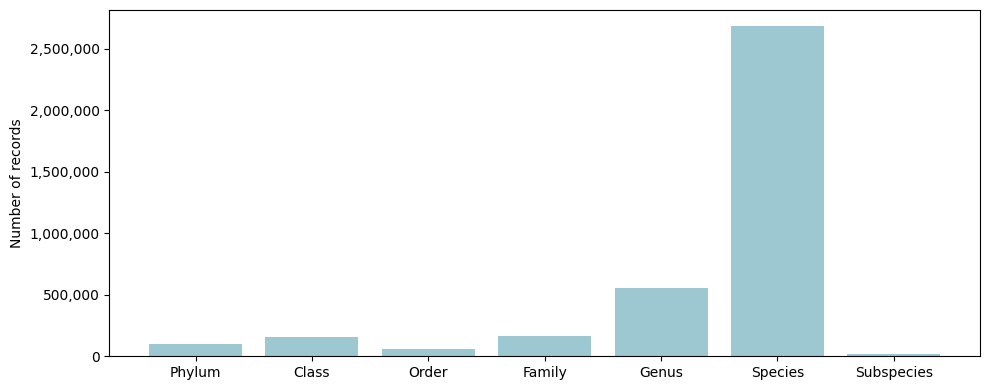

In [21]:
#| label: fig-tax_resolution
#| fig-cap: "Taxonomic resolution of all records of benthic invertebrates in the BENTH-MARC data collection. The bars show records per rank from phylum to species."
#| fig-pos: "H"

# Load data
merged_path = 'Final/merged_all_final.parquet'
df_merged = pd.read_parquet(merged_path)

# Ensure required column exists
if 'taxonRank' not in df_merged.columns:
    raise KeyError("Column 'taxonRank' not found in Final/merged_all_final.parquet")

# Normalize rank values for consistent matching and display labels
rank_series = df_merged['taxonRank'].fillna('').astype(str).str.strip().str.lower().str.capitalize()

# Keep the exact order requested (title case for display)
target_order = ['Phylum', 'Class', 'Order', 'Family', 'Genus', 'Species', 'Subspecies']

# Count records per requested rank
rank_counts = rank_series.value_counts(dropna=False)
target_counts = rank_counts.reindex(target_order, fill_value=0).astype(int)

# DataFrame for plotting
rank_counts_df = target_counts.rename_axis('Rank').reset_index(name='Count')

# Plot
color = '#9DC8D2'
plt.figure(figsize=(10, 4))
plt.bar(rank_counts_df['Rank'], rank_counts_df['Count'], color=color)
plt.ylabel('Number of records', fontsize=10)
plt.xticks(rotation=0, fontsize=10)
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.savefig("Figures/taxonomic_levels.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [18]:
#| include: false
# # Normalize phylum values for robust matching
if 'all_merged' in globals():
    source_df = all_merged
elif 'all_merged_df' in globals():
    source_df = all_merged
else:
    source_df = pd.read_parquet('Final/merged_all_final.parquet')

phylum_norm = source_df['phylum'].astype(str).str.strip().str.lower()
total_records = len(source_df)

percent_annelida = (phylum_norm == 'annelida').sum() / total_records * 100 if total_records > 0 else 0.0
percent_mollusca = (phylum_norm == 'mollusca').sum() / total_records * 100 if total_records > 0 else 0.0
percent_arthropoda = (phylum_norm == 'arthropoda').sum() / total_records * 100 if total_records > 0 else 0.0

print(f"percent_annelida: {percent_annelida:.2f}%")
print(f"percent_mollusca: {percent_mollusca:.2f}%")
print(f"percent_arthropoda: {percent_arthropoda:.2f}%")

unique_taxa_arthropoda = source_df.loc[
    phylum_norm == 'arthropoda', 'aphiaID'
].nunique()

print(f"unique_taxa_arthropoda: {unique_taxa_arthropoda}")

percent_annelida: 44.44%
percent_mollusca: 20.86%
percent_arthropoda: 16.99%
unique_taxa_arthropoda: 3255


In [19]:
display(Markdown(
    f"@fig-top10phyla shows an overview of the top ten most record-rich phyla in BENTH-MARC. The number of records is compared to the number of unique taxa per "
    f"phylum. Annelida is by far the phylum with the highest number of records, with a share of {percent_annelida:.0f}% of the total number of records. However, the highest number of unique taxa "
    f"can be found within the phylum Arthropoda, even though it only has {percent_arthropoda:.0f}% of the total number of records. The phylum Bryozoa stands out in terms of having the highest taxa to records ratio. "
))

@fig-top10phyla shows an overview of the top ten most record-rich phyla in BENTH-MARC. The number of records is compared to the number of unique taxa per phylum. Annelida is by far the phylum with the highest number of records, with a share of 44% of the total number of records. However, the highest number of unique taxa can be found within the phylum Arthropoda, even though it only has 17% of the total number of records. The phylum Bryozoa stands out in terms of having the highest taxa to records ratio. 

In [76]:
#--- FIGURE with top 10 phyla by unique taxa and nr of records ---

In [22]:
# Load the parquet file and compute rank-split metrics by phylum
df_main = pd.read_parquet('Final/merged_all_final.parquet')
df_main.columns = [c.strip() for c in df_main.columns]
phylum_col = 'phylum'
accepted_col = 'aphiaID'
rank_col = 'taxonRank'

required_cols = [phylum_col, accepted_col, rank_col]
missing = [c for c in required_cols if c not in df_main.columns]
if missing:
    raise KeyError(f"Missing required column(s): {missing}")

# Normalize rank values
rank_norm = df_main[rank_col].astype(str).str.strip().str.upper()

# Record counts (left side): total + SPECIES subset
total_records = df_main.groupby(phylum_col, dropna=False).size().reset_index(name='records_total')
species_records = (
    df_main[rank_norm == 'SPECIES']
    .groupby(phylum_col, dropna=False)
    .size()
    .reset_index(name='records_species')
)

# Unique AphiaIDs (right side): treat an AphiaID as species-level if any row is SPECIES
df_main[accepted_col] = pd.to_numeric(df_main[accepted_col], errors='coerce')
species_unique = (
    df_main.dropna(subset=[accepted_col])
    .assign(is_species=(rank_norm == 'SPECIES'))
    .groupby([phylum_col, accepted_col], dropna=False)['is_species']
    .max()
    .reset_index()
    .groupby(phylum_col, dropna=False)['is_species']
    .agg(unique_species='sum', unique_total='size')
    .reset_index()
)

metrics = (
    total_records.merge(species_records, on=phylum_col, how='left')
    .merge(species_unique, on=phylum_col, how='left')
    .fillna(0)
)
metrics['records_total'] = metrics['records_total'].astype(int)
metrics['records_species'] = metrics['records_species'].astype(int)
metrics['records_other'] = (metrics['records_total'] - metrics['records_species']).astype(int)
metrics['unique_total'] = metrics['unique_total'].astype(int)
metrics['unique_species'] = metrics['unique_species'].astype(int)
metrics['unique_other'] = (metrics['unique_total'] - metrics['unique_species']).astype(int)

# Union selection (top 10 by each metric)
top10_records = metrics.sort_values('records_total', ascending=False).head(10)[phylum_col].tolist()
top10_unique = metrics.sort_values('unique_total', ascending=False).head(10)[phylum_col].tolist()
selected_union = list(dict.fromkeys(top10_records + top10_unique))

# Order by total records for plotting
df_union = metrics[metrics[phylum_col].isin(selected_union)].copy()
order_union = df_union.sort_values('records_total', ascending=False)[phylum_col].tolist()

# Overall species shares across selected phyla (for annotation)
total_records_union = df_union['records_total'].sum()
species_records_union = df_union['records_species'].sum()
records_species_pct_union = (species_records_union / total_records_union * 100) if total_records_union > 0 else 0.0

total_unique_union = df_union['unique_total'].sum()
species_unique_union = df_union['unique_species'].sum()
unique_species_pct_union = (species_unique_union / total_unique_union * 100) if total_unique_union > 0 else 0.0

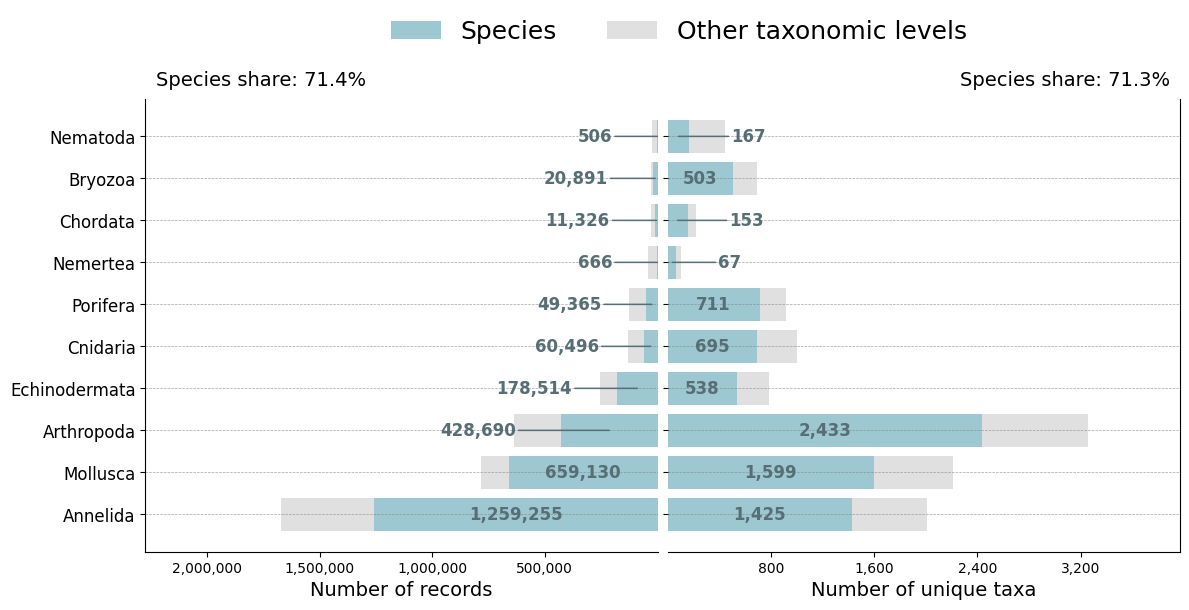

In [23]:
#| label: fig-top10phyla
#| fig-cap: "The number of records (left side) and taxa (right side)of the ten most records-rich phyla of benthic invertebrates in the BENTH-MARC database. The proportion of species-level data is indicated in teal and by numbers in the bar plot, while grey indicates data on other taxonomic levels. "
#| fig-pos: "H"

# Plot mirrored stacked barplot (UNION of top-10 by each metric)
# Left: records, Right: unique AphiaIDs
phylum_col = 'phylum'
plot_df = df_union.set_index(phylum_col).loc[order_union].reset_index()

species_color = '#9DC8D2'
other_color = '#E0E0E0'

# Darker text shade for species labels
species_label_color = mcolors.to_hex(np.array(mcolors.to_rgb(species_color)) * 0.55)

fig, (ax_left, ax_right) = plt.subplots(
    ncols=2,
    figsize=(12, max(6, int(len(order_union) * 0.6))),
    gridspec_kw={'width_ratios': [1, 1]}
)

y = np.arange(len(plot_df))

# Left side (records): negative values to mirror
ax_left.barh(y, -plot_df['records_species'], color=species_color, label='Species')
ax_left.barh(y, -plot_df['records_other'], left=-plot_df['records_species'], color=other_color, label='Other ranks')

# Right side (unique AphiaIDs): positive values
ax_right.barh(y, plot_df['unique_species'], color=species_color, label='Species')
ax_right.barh(y, plot_df['unique_other'], left=plot_df['unique_species'], color=other_color, label='Other ranks')

left_max = float(plot_df['records_total'].max())
right_max = float(plot_df['unique_total'].max())

# Axes formatting with room for outside species labels
ax_left.set_xlabel('Number of records', fontsize=14)
ax_left.set_xlim(-left_max * 1.36, 0)
ax_left.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(abs(x)):,}'))
ax_left.xaxis.set_major_locator(MaxNLocator(nbins=5, prune='both'))
ax_left.spines['right'].set_visible(False)
ax_left.spines['top'].set_visible(False)

ax_right.set_xlabel('Number of unique taxa', fontsize=14)
ax_right.set_xlim(0, right_max * 1.22)
ax_right.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(x):,}'))
ax_right.xaxis.set_major_locator(MaxNLocator(nbins=5, prune='both'))
ax_right.spines['left'].set_visible(False)
ax_right.spines['top'].set_visible(False)

# Add gridlines
ax_left.grid(axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
ax_right.grid(axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7)

# Explicit y-ticks and labels
ax_left.set_yticks(y)
ax_left.set_yticklabels(order_union, fontsize=12)
ax_right.set_yticks(y)
ax_right.set_yticklabels([])

# Draw once so renderer is available for text-size checks
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

def text_fits_segment(ax, text, x_center, y_center, seg_width, pad_px=8, fontsize=12, fontweight='bold'):
    tmp = ax.text(x_center, y_center, text, fontsize=fontsize, fontweight=fontweight, alpha=0.0)
    bb = tmp.get_window_extent(renderer=renderer)
    tmp.remove()

    x0 = ax.transData.transform((x_center - seg_width / 2.0, y_center))[0]
    x1 = ax.transData.transform((x_center + seg_width / 2.0, y_center))[0]
    seg_px = abs(x1 - x0)
    return bb.width <= max(0, seg_px - pad_px)

left_outside_offset = left_max * 0.12
right_outside_offset = right_max * 0.10

# Add species labels only: inside when fit, otherwise outside with connector lines
for i, row in plot_df.iterrows():
    rec_species = int(row['records_species'])
    uniq_species = int(row['unique_species'])

    rec_species_str = f"{rec_species:,}"
    uniq_species_str = f"{uniq_species:,}"

    # Left panel species labels
    rec_species_center = -rec_species / 2.0
    rec_species_edge = -rec_species

    if rec_species > 0 and text_fits_segment(ax_left, rec_species_str, rec_species_center, y[i], rec_species):
        ax_left.text(
            rec_species_center, y[i], rec_species_str,
            ha='center', va='center', fontsize=12,
            color=species_label_color, fontweight='bold'
        )
    else:
        rec_label_x = rec_species_edge - left_outside_offset
        ax_left.annotate(
            rec_species_str,
            xy=(rec_species_center, y[i]),
            xytext=(rec_label_x, y[i]),
            ha='right', va='center',
            fontsize=12, color=species_label_color, fontweight='bold',
            arrowprops=dict(arrowstyle='-', color=species_label_color, lw=1.1, shrinkA=0, shrinkB=0)
        )

    # Right panel species labels
    uniq_species_center = uniq_species / 2.0
    uniq_species_edge = uniq_species

    if uniq_species > 0 and text_fits_segment(ax_right, uniq_species_str, uniq_species_center, y[i], uniq_species):
        ax_right.text(
            uniq_species_center, y[i], uniq_species_str,
            ha='center', va='center', fontsize=12,
            color=species_label_color, fontweight='bold'
        )
    else:
        uniq_label_x = uniq_species_edge + right_outside_offset
        ax_right.annotate(
            uniq_species_str,
            xy=(uniq_species_center, y[i]),
            xytext=(uniq_label_x, y[i]),
            ha='left', va='center',
            fontsize=12, color=species_label_color, fontweight='bold',
            arrowprops=dict(arrowstyle='-', color=species_label_color, lw=1.1, shrinkA=0, shrinkB=0)
        )

# Show overall species shares in each metric
ax_left.text(
    0.02, 1.02,
    f"Species share: {records_species_pct_union:.1f}%",
    transform=ax_left.transAxes,
    fontsize=14,
    ha='left',
    va='bottom'
)
ax_right.text(
    0.98, 1.02,
    f"Species share: {unique_species_pct_union:.1f}%",
    transform=ax_right.transAxes,
    fontsize=14,
    ha='right',
    va='bottom'
)

# Shared legend
legend_handles = [
    Patch(facecolor=species_color, edgecolor='none', label='Species'),
    Patch(facecolor=other_color, edgecolor='none', label='Other taxonomic levels')
]
fig.legend(
    handles=legend_handles,
    loc='upper center',
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.57, 1.03),
    fontsize=18
)

plt.tight_layout()
plt.subplots_adjust(top=0.86, wspace=0.02)

outfile_labels = 'Figures/toptenphyla.png'
plt.savefig(outfile_labels, dpi=220, bbox_inches='tight')
plt.show()

In [24]:
#| include: false
# Load the data
all_merged = pd.read_parquet("Final/merged_all_final.parquet")

# Strict usable-info check: exclude nulls and placeholder-like text values
def has_info(series):
    vals = series.astype('string').str.strip().str.lower()
    return ~(series.isna() | vals.isin(['', 'nan', 'none', '<na>']))

# Calculate biomass percentage
biomass_pct = (
    (has_info(all_merged['biomass']) & has_info(all_merged['areaSampled'])).sum() / len(all_merged)
) * 100

# Calculate abundance percentage (both individualCount AND areaSampled must be truly usable)
abundance_pct = (
    (has_info(all_merged['individualCount']) & has_info(all_merged['areaSampled'])).sum() / len(all_merged)
) * 100

# Calculate gear percentage
gear_pct = (all_merged['gear'].notna().sum() / len(all_merged)) * 100

# Display results
print(f"Biomass percentage: {biomass_pct:.2f}%")
print(f"Abundance percentage: {abundance_pct:.2f}%")
print(f"Gear percentage: {gear_pct:.2f}%")

Biomass percentage: 6.68%
Abundance percentage: 7.09%
Gear percentage: 70.32%


In [31]:
display(Markdown(
    f"The records in BENTH-MARC have varying degrees of associated information about biomass, occurrence metrics and sampling gear (@fig-panelmap a-c). We have considered only records with information about " 
    f"both biomass or number of individuals and sampling area to be true biomass or abundance records, as no standardization methods can be applied on records where only one of these is known. " 
    f"Stations with full biomass coverage and abundance data are "
    f"mainly located in the Barents Sea, Norwegian Sea, Chukchi Sea and Laptev Sea. In terms of the number of records, {biomass_pct:.1f}% have biomass data and {abundance_pct:.1f}% have abundance data. " 
    f"Since stations can have a combination of records with and without biomass coverage as well as a combination of records with different types of occurrence metrics, the categories partial (biomass coverage) "
    f"and mixed (occurrence metrics) are displayed in the maps (@fig-panelmap a-b). In addition, {gear_pct:.1f}% of the records have associated information about sampling gear (@fig-panelmap c). "
))

The records in BENTH-MARC have varying degrees of associated information about biomass, occurrence metrics and sampling gear (@fig-panelmap a-c). We have considered only records with information about both biomass or number of individuals and sampling area to be true biomass or abundance records, as no standardization methods can be applied on records where only one of these is known. Stations with full biomass coverage and abundance data are mainly located in the Barents Sea, Norwegian Sea, Chukchi Sea and Laptev Sea. In terms of the number of records, 6.7% have biomass data and 7.1% have abundance data. Since stations can have a combination of records with and without biomass coverage as well as a combination of records with different types of occurrence metrics, the categories partial (biomass coverage) and mixed (occurrence metrics) are displayed in the maps (@fig-panelmap a-b). In addition, 70.3% of the records have associated information about sampling gear (@fig-panelmap c). 

In [29]:
#| include: false
# Use station-level unique AphiaID counts from df_taxa when available; otherwise load fallback data
df_taxa_local = globals().get('df_taxa', None)

if isinstance(df_taxa_local, pd.DataFrame) and 'uniqueAphiaIDCount' in df_taxa_local.columns:
	taxa_counts = pd.to_numeric(df_taxa_local['uniqueAphiaIDCount'], errors='coerce').dropna()
else:
	taxa_path = 'Final/all_stations.parquet'
	df_taxa_fallback = pd.read_parquet(taxa_path)

	if 'uniqueAphiaIDCount' in df_taxa_fallback.columns:
		taxa_counts = pd.to_numeric(df_taxa_fallback['uniqueAphiaIDCount'], errors='coerce').dropna()
	else:
		# Last resort: compute unique AphiaIDs per station from all_merged
		if 'all_merged' not in globals():
			all_merged = pd.read_parquet('..//All data//all_merged.parquet')

		needed = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart', 'year', 'aphiaID']
		missing_cols = [c for c in needed if c not in all_merged.columns]
		if missing_cols:
			raise KeyError(f"Missing required column(s): {missing_cols}")

		tmp = all_merged[needed].copy()
		tmp['decimalLatitudeStart'] = pd.to_numeric(tmp['decimalLatitudeStart'], errors='coerce').round(5)
		tmp['decimalLongitudeStart'] = pd.to_numeric(tmp['decimalLongitudeStart'], errors='coerce').round(5)
		tmp['year'] = pd.to_numeric(tmp['year'], errors='coerce').round().astype('Int64')
		tmp = tmp.dropna(subset=['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart'])

		taxa_counts = tmp.groupby(
			['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart', 'year'],
			dropna=False
		)['aphiaID'].nunique()

# Percent of stations with < 10 AphiaIDs
pct_lt_10 = (taxa_counts < 10).mean() * 100 if len(taxa_counts) > 0 else np.nan

# 90th percentile AphiaIDs per station
p90_taxa = taxa_counts.quantile(0.90) if len(taxa_counts) > 0 else np.nan

# Optional integer threshold form (useful for text like "90% have less than X")
x_for_90pct_lt = int(np.ceil(p90_taxa)) if pd.notna(p90_taxa) else None

# Highest number of AphiaIDs at one station
max_taxa = int(taxa_counts.max()) if len(taxa_counts) > 0 else None

# Lowest number of AphiaIDs at one station
min_taxa = int(taxa_counts.min()) if len(taxa_counts) > 0 else None

print(f"Stations with <10 AphiaIDs: {pct_lt_10:.1f}%")
print(f"90th percentile AphiaIDs per station: {p90_taxa:.1f}")
print(f"Highest AphiaIDs at one station: {max_taxa}")
print(f"Lowest AphiaIDs at one station: {min_taxa}")

Stations with <10 AphiaIDs: 82.4%
90th percentile AphiaIDs per station: 32.0
Highest AphiaIDs at one station: 237
Lowest AphiaIDs at one station: 1


In [32]:

display(Markdown(
    f"The vast majority of stations have low numbers of records (@fig-panelmap d), with {pct_lt_10:.0f}% having fewer than ten records per station, and 90% having fewer than {x_for_90pct_lt} records per station. The lowest number of records "
    f"per station is one and the highest number is {max_taxa}. "
))

The vast majority of stations have low numbers of records (@fig-panelmap d), with 82% having fewer than ten records per station, and 90% having fewer than 32 records per station. The lowest number of records per station is one and the highest number is 237. 

In [35]:
# Prepare data for fig-panelmap from all_merged.parquet
panel_cols = [
    'datasetKey',
    'decimalLatitudeStart',
    'decimalLongitudeStart',
    'year',
    'startDayOfYear',
    'biomass',
    'individualCount',
    'areaSampled'
]

df_panel = pd.read_parquet('Final/merged_all_final.parquet', columns=panel_cols).copy()

station_cols_required = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart', 'startDayOfYear']

# Keep station coordinates at full precision and include startDayOfYear in station key
df_panel['decimalLatitudeStart'] = pd.to_numeric(df_panel['decimalLatitudeStart'], errors='coerce')
df_panel['decimalLongitudeStart'] = pd.to_numeric(df_panel['decimalLongitudeStart'], errors='coerce')
df_panel['year'] = pd.to_numeric(df_panel['year'], errors='coerce').astype('Int64')
df_panel['startDayOfYear'] = pd.to_numeric(df_panel['startDayOfYear'], errors='coerce').astype('Int64')

station_key = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart', 'year', 'startDayOfYear']


def has_info(series):
    vals = series.astype('string').str.strip().str.lower()
    return ~(series.isna() | vals.isin(['', 'nan', 'none', '<na>']))

# Record-level flags
df_panel['has_biomass'] = has_info(df_panel['biomass']) & has_info(df_panel['areaSampled'])
df_panel['is_abundance'] = has_info(df_panel['individualCount']) & has_info(df_panel['areaSampled'])

# ---------------- Biomass coverage ----------------
biomass_station = (
    df_panel.groupby(station_key, dropna=False, as_index=False)['has_biomass']
            .agg(n_with='sum', n_total='count')
)
biomass_station['biomass_coverage'] = np.select(
    [biomass_station['n_with'] == 0, biomass_station['n_with'] == biomass_station['n_total']],
    ['None', 'Full'],
    default='partial'
)

coords_biomass = biomass_station.rename(
    columns={'decimalLongitudeStart': 'lon', 'decimalLatitudeStart': 'lat'}
)[['lon', 'lat', 'biomass_coverage']].copy()
coords_biomass = coords_biomass[
    (coords_biomass['lat'] >= -90) & (coords_biomass['lat'] <= 90) &
    (coords_biomass['lon'] >= -180) & (coords_biomass['lon'] <= 180)
]

drawing_order_biomass = ['None', 'partial', 'Full']
coverage_colors = {
    'None': '#9DC8D2',
    'partial': '#F1C40F',
    'Full': '#2C3E50'
}

records_biomass = pd.Series({
    'None': int((~df_panel['has_biomass']).sum()),
    'Full': int(df_panel['has_biomass'].sum())
})
total_obs = int(records_biomass.sum())
labels_biomass = ['None', 'Full']
counts_biomass = [records_biomass['None'], records_biomass['Full']]
colors_biomass = ['#9DC8D2', '#2C3E50']

# ---------------- Occurrence metrics ----------------
# Record-level classification: abundance requires BOTH individualCount and areaSampled
df_panel['metric_record'] = np.where(df_panel['is_abundance'], 'Abundance', 'Presence')

metric_station = (
    df_panel.groupby(station_key, dropna=False, as_index=False)['metric_record']
            .nunique()
            .rename(columns={'metric_record': 'n_metric_types'})
)
any_abundance = (
    df_panel.groupby(station_key, dropna=False)['is_abundance']
            .any()
            .rename('any_abundance')
            .reset_index()
)
metric_station = metric_station.merge(any_abundance, on=station_key, how='left')
metric_station['metric_category'] = np.select(
    [
        metric_station['n_metric_types'] > 1,
        metric_station['any_abundance']
    ],
    ['Mixed', 'Abundance'],
    default='Presence'
)

coords_metric = metric_station.rename(
    columns={'decimalLongitudeStart': 'lon', 'decimalLatitudeStart': 'lat'}
)[['lon', 'lat', 'metric_category']].copy()
coords_metric = coords_metric[
    (coords_metric['lat'] >= -90) & (coords_metric['lat'] <= 90) &
    (coords_metric['lon'] >= -180) & (coords_metric['lon'] <= 180)
]

drawing_order_metric = ['Presence', 'Mixed', 'Abundance']
colors_metric = {
    'Presence': '#9DC8D2',
    'Mixed': '#F1C40F',
    'Abundance': '#2C3E50'
}

plot_df = (
    df_panel['metric_record']
    .value_counts()
    .reindex(['Presence', 'Abundance'], fill_value=0)
    .rename_axis('Metric')
    .reset_index(name='Count')
)
plot_df['Percent'] = np.where(plot_df['Count'].sum() > 0, (plot_df['Count'] / plot_df['Count'].sum()) * 100.0, 0.0)


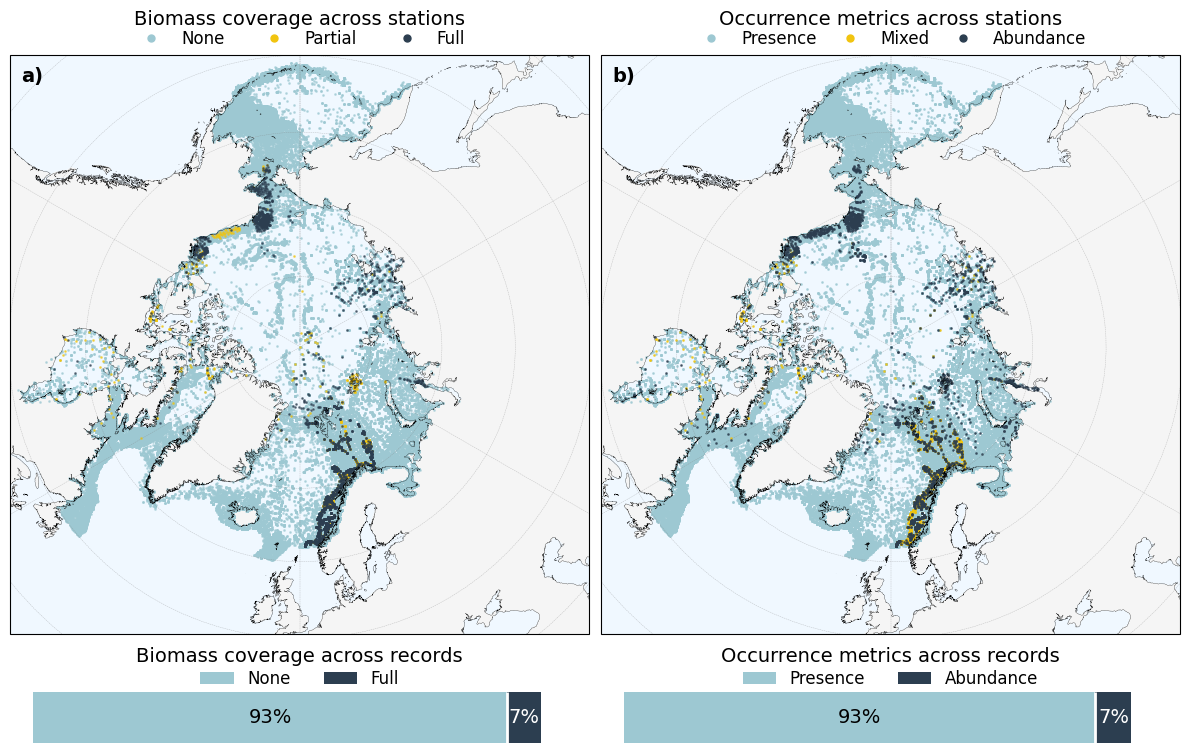

In [36]:
#| fig-pos: "H"
#| fig-subcap: []
#| fig-names: false

# Create a figure with a custom grid layout
fig = plt.figure(figsize=(12, 10))
gs = gridspec.GridSpec(
    2, 2,  # 2 rows, 2 columns
    width_ratios=[1, 1],  # Adjust the width of each column
    height_ratios=[2, 0.1]  # Adjust the height of each row
)
# Plot 1: Biomass Coverage Map 
ax1 = fig.add_subplot(gs[0, 0], projection=ccrs.NorthPolarStereo())
ax1.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax1.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax1.coastlines(resolution='10m', linewidth=0.2, color='black')
ax1.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
for coverage_type in drawing_order_biomass:
    subset = coords_biomass[coords_biomass['biomass_coverage'] == coverage_type]
    ax1.scatter(subset['lon'].values, subset['lat'].values,
                s=1, color=coverage_colors[coverage_type], alpha=0.6,
                label=coverage_type.capitalize(), transform=ccrs.PlateCarree())
legend_handles_biomass_map = [
    mpl.lines.Line2D([0], [0], marker='o', linestyle='None',
                     markerfacecolor=coverage_colors[k], markeredgecolor=coverage_colors[k],
                     markersize=5, label=k.capitalize())
    for k in drawing_order_biomass
]
ax1.legend(handles=legend_handles_biomass_map, loc='upper center', bbox_to_anchor=(0.5, 1.07), fontsize=12, ncol=3, frameon=False)
ax1.set_title('Biomass coverage across stations', pad=22, fontsize=14)
ax1.text(0.02, 0.98, 'a)', transform=ax1.transAxes, ha='left', va='top', fontsize=14, fontweight='bold', zorder=10)

# Plot 2: Sampling Metrics Map (Top-right, larger height)
ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.NorthPolarStereo())
ax2.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax2.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax2.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax2.coastlines(resolution='10m', linewidth=0.2, color='black')
ax2.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
for cat in drawing_order_metric:
    sub = coords_metric[coords_metric['metric_category'] == cat]
    ax2.scatter(sub['lon'].values, sub['lat'].values, s=1,
                color=colors_metric.get(cat, 'lightgray'), alpha=0.7,
                label=cat.capitalize(), transform=ccrs.PlateCarree())
legend_handles_metric_map = [
    mpl.lines.Line2D([0], [0], marker='o', linestyle='None',
                     markerfacecolor=colors_metric[k], markeredgecolor=colors_metric[k],
                     markersize=5, label=k)
    for k in drawing_order_metric
]
ax2.legend(handles=legend_handles_metric_map, loc='upper center', bbox_to_anchor=(0.5, 1.07), fontsize=12, ncol=3, frameon=False, columnspacing=1)
ax2.set_title('Occurrence metrics across stations', pad=22, fontsize=14)
ax2.text(0.02, 0.98, 'b)', transform=ax2.transAxes, ha='left', va='top', fontsize=14, fontweight='bold', zorder=10)

# Use the original two-category barplot order and colors
order_metrics = ['Presence', 'Abundance']
color_map_metrics = {'Presence': '#9DC8D2', 'Abundance': '#2C3E50'}

# Plot 3: Biomass Records Bar Plot (Bottom-left, smaller height)
ax3 = fig.add_subplot(gs[1, 0])
left_val = 0.0
for i, count in enumerate(counts_biomass):
    bar_color = colors_biomass[i]
    ax3.barh([0], [count], left=left_val, color=bar_color, edgecolor='none', linewidth=0)
    pct = 0 if total_obs == 0 else count / total_obs * 100.0
    x_mid = left_val + count / 2.0
    # Determine text color based on bar color brightness
    rgb = mcolors.to_rgb(bar_color)
    brightness = rgb_to_hsv(rgb)[2]  # Get the value (brightness) from HSV
    text_color = 'white' if brightness < 0.5 else 'black'
    ax3.text(x_mid, 0, f'{pct:.0f}%', ha='center', va='center', fontsize=14, color=text_color)
    left_val += count
# Add small white gaps between segments
gap_left = 0.0
for count in counts_biomass[:-1]:
    gap_left += count
    ax3.vlines(gap_left, -0.4, 0.4, colors='white', linewidth=2)
# Style for Plot 3
ax3.set_xticks([])
ax3.set_yticks([])
ax3.set_title('Biomass coverage across records', pad=20, fontsize=14)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.spines['left'].set_visible(False)
ax3.spines['bottom'].set_visible(False)
ax3.grid(False)
# Add legend for Plot 3
legend_handles = [Patch(facecolor=colors_biomass[i], edgecolor='none', label=labels_biomass[i]) for i in range(len(labels_biomass))]
ax3.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.6),  # Position the legend below the plot
    ncol=2,  # Number of columns in the legend
    frameon=False,  # Remove the legend box
    fontsize=12,
)
# Plot 4: Sampling Metrics Bar Plot (Bottom-right, smaller height)
ax4 = fig.add_subplot(gs[1, 1])
left_val = 0.0
for m in order_metrics:
    val = float(plot_df.loc[plot_df['Metric'] == m, 'Percent'].values[0]) if m in list(plot_df['Metric']) else 0.0
    bar_color = color_map_metrics[m]
    ax4.barh([0], [val], left=left_val, color=bar_color, edgecolor='none', linewidth=0)
    # Determine text color based on bar color brightness
    rgb = mcolors.to_rgb(bar_color)
    brightness = rgb_to_hsv(rgb)[2]  # Get the value (brightness) from HSV
    text_color = 'white' if brightness < 0.5 else 'black'
    ax4.text(left_val + val / 2, 0, f'{val:.0f}%', ha='center', va='center', fontsize=14, color=text_color)
    left_val += val
# Add small white gaps between segments
gap_left = 0.0
for m in order_metrics[:-1]:
    # Safely get percent for the metric, default to 0.0 when missing
    val_gap = float(plot_df.loc[plot_df['Metric'] == m, 'Percent'].values[0]) if m in list(plot_df['Metric']) else 0.0
    gap_left += val_gap
    ax4.vlines(gap_left, -0.4, 0.4, colors='white', linewidth=2)
# Style for Plot 4
ax4.set_xticks([])
ax4.set_yticks([])
ax4.set_title('Occurrence metrics across records', pad=20, fontsize=14)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.spines['left'].set_visible(False)
ax4.spines['bottom'].set_visible(False)
ax4.grid(False)
# Add legend for Plot 4
legend_handles = [Patch(facecolor=color_map_metrics[m], edgecolor='none', label=m) for m in order_metrics]
ax4.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.6),  # Position the legend below the plot
    ncol=2,  # Number of columns in the legend
    frameon=False,  #Remove the legend box
    fontsize=12,
)
# Adjust layout
plt.tight_layout()
plt.subplots_adjust(hspace=-0.375, wspace=0.02)
# Center the bottom bars under their corresponding maps
pos1 = ax1.get_position()
pos2 = ax2.get_position()
pos3 = ax3.get_position()
pos4 = ax4.get_position()
bar_width_scale = 0.92
new_w1 = pos1.width * bar_width_scale
new_w2 = pos2.width * bar_width_scale
ax3.set_position([pos1.x0 + (pos1.width - new_w1) / 2, pos3.y0, new_w1, pos3.height])
ax4.set_position([pos2.x0 + (pos2.width - new_w2) / 2, pos4.y0, new_w2, pos4.height])
 
plt.savefig('Figures/panel_biomass_abundance.png', dpi=300, bbox_inches='tight', facecolor='white')



In [37]:
# Load and process data for the map (Number of records per station)
station_counts_path = 'Final/all_stations.parquet'
df_taxa = pd.read_parquet(station_counts_path)

# Validate required records column
if 'uniqueAphiaIDCount' not in df_taxa.columns:
    raise KeyError("Column 'uniqueAphiaIDCount' not found in Final/all_stations.parquet")

# Shared station definition used in the manuscript, year and startDayOfYear optional
station_cols_full = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart', 'year', 'startDayOfYear']
station_cols_required = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart']


def apply_station_definition(df, value_cols):
    """Apply station-level de-duplication; keep rows with missing optional fields."""
    if set(station_cols_required).issubset(df.columns):
        out = df.copy()
        out['decimalLatitudeStart'] = pd.to_numeric(out['decimalLatitudeStart'], errors='coerce')
        out['decimalLongitudeStart'] = pd.to_numeric(out['decimalLongitudeStart'], errors='coerce')

        if 'year' in out.columns:
            out['year'] = pd.to_numeric(out['year'], errors='coerce').round().astype('Int64')

        if 'startDayOfYear' in out.columns:
            out['startDayOfYear'] = pd.to_numeric(out['startDayOfYear'], errors='coerce').astype('Int64')

        # Do NOT drop rows missing optional fields; keep them as NaN/Int64
        dedupe_cols = station_cols_required + ([ 'year' ] if 'year' in out.columns else []) + ([ 'startDayOfYear' ] if 'startDayOfYear' in out.columns else [])
        keep_cols = dedupe_cols + [c for c in value_cols if c in out.columns]
        return out[keep_cols].drop_duplicates(dedupe_cols)

    return df.copy()


# Apply station definition for taxa map when station columns are available
df_taxa = apply_station_definition(df_taxa, value_cols=['uniqueAphiaIDCount'])

# Standardize coordinate column names for downstream plotting
lon_candidates = ['decimalLongitudeStart', 'LonStart', 'decimalLongitude', 'lon', 'longitude']
lat_candidates = ['decimalLatitudeStart', 'LatStart', 'decimalLatitude', 'lat', 'latitude']

lon_col = next((c for c in lon_candidates if c in df_taxa.columns), None)
lat_col = next((c for c in lat_candidates if c in df_taxa.columns), None)

if lon_col is None or lat_col is None:
    raise KeyError("Could not find station longitude/latitude columns in Final/all_stations.parquet")

plot_df_taxa = (
    df_taxa.rename(columns={lon_col: 'lon', lat_col: 'lat'})
          .copy()
)
plot_df_taxa['lon'] = pd.to_numeric(plot_df_taxa['lon'], errors='coerce')
plot_df_taxa['lat'] = pd.to_numeric(plot_df_taxa['lat'], errors='coerce')
plot_df_taxa['uniqueAphiaIDCount'] = pd.to_numeric(plot_df_taxa['uniqueAphiaIDCount'], errors='coerce')
plot_df_taxa = plot_df_taxa.dropna(subset=['lon', 'lat', 'uniqueAphiaIDCount'])
plot_df_taxa = plot_df_taxa[
    (plot_df_taxa['lat'] >= -90) & (plot_df_taxa['lat'] <= 90) &
    (plot_df_taxa['lon'] >= -180) & (plot_df_taxa['lon'] <= 180)
]
plot_df_taxa = plot_df_taxa.sort_values('uniqueAphiaIDCount', ascending=True)

# Load and process data for binary gear-information map (station level)
stations_gear_path = 'Final/all_stations.parquet'
df_gear_station = pd.read_parquet(stations_gear_path)

# Apply the same station definition for station-level gear data (year and startDayOfYear can be missing)
df_gear_station = apply_station_definition(df_gear_station, value_cols=['gear'])

lon_col_gear = next((c for c in lon_candidates if c in df_gear_station.columns), None)
lat_col_gear = next((c for c in lat_candidates if c in df_gear_station.columns), None)

if lon_col_gear is None or lat_col_gear is None:
    raise KeyError("Could not find station longitude/latitude columns in Final/all_stations.parquet")
if 'gear' not in df_gear_station.columns:
    raise KeyError("Column 'gear' not found in Final/all_stations.parquet")

coords_gear = df_gear_station.rename(columns={lon_col_gear: 'lon', lat_col_gear: 'lat'})[['lon', 'lat', 'gear']].copy()
coords_gear['lon'] = pd.to_numeric(coords_gear['lon'], errors='coerce')
coords_gear['lat'] = pd.to_numeric(coords_gear['lat'], errors='coerce')

gear_norm = coords_gear['gear'].astype('string').str.strip().str.lower()
missing_tokens = {'', 'nan', 'none', '<na>'}
coords_gear['gear_info'] = np.where(
    coords_gear['gear'].isna() | gear_norm.isin(missing_tokens),
    'No gear info',
    'With gear info'
)

coords_gear = coords_gear.dropna(subset=['lon', 'lat'])
coords_gear = coords_gear[
    (coords_gear['lat'] >= -90) & (coords_gear['lat'] <= 90) &
    (coords_gear['lon'] >= -180) & (coords_gear['lon'] <= 180)
]

colors_gear = {'No gear info': '#9DC8D2', 'With gear info': '#2C3E50'}
drawing_order_gear = ['No gear info', 'With gear info']

# Prepare data for the gear information bar plot (record level)
df_merged_gear = pd.read_parquet('Final/merged_all_final.parquet', columns=['gear'])

gear_series = df_merged_gear['gear']
has_gear_info = gear_series.notna()
no_gear_info = gear_series.isna()

n_records = len(gear_series)
pct_with_gear = (float(has_gear_info.sum()) / float(n_records) * 100.0) if n_records > 0 else 0.0
pct_without_gear = (float(no_gear_info.sum()) / float(n_records) * 100.0) if n_records > 0 else 0.0

plot_df_gear = pd.DataFrame({
    'Gear info': ['With gear info', 'No gear info'],
    'Percent': [pct_with_gear, pct_without_gear]
})
order_gear = ['With gear info', 'No gear info']
color_map_gear = {'With gear info': '#2C3E50', 'No gear info': '#9DC8D2'}


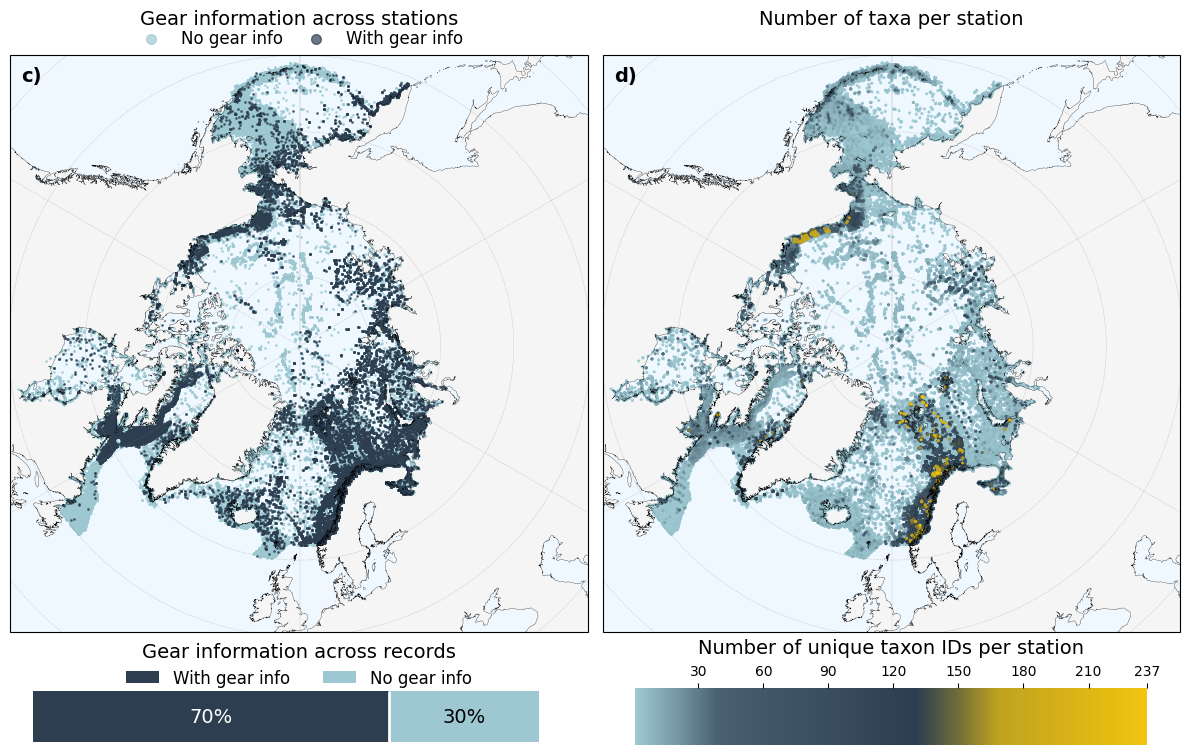

In [38]:
#| fig-pos: "H"
#| label: fig-panelmap
#| fig-cap: "Benthic invertebrates in BENTH-MARC by a) biomass coverage, b) occurrence metrics and c) gear information across stations and records, as well as d) number of unique taxa per station. In 4 d), stations with higher numbers of taxa are drawn on top of stations with lower numbers of taxa."


# ------------------------------ NEXT FIGURE -----------------------------------------


# Create a figure with a custom grid layout
fig = plt.figure(figsize=(12, 10))
gs = gridspec.GridSpec(
    2, 2,  # 2 rows, 2 columns
    width_ratios=[1, 1],  # Adjust the width of each column
    height_ratios=[2, 0.1]  # Adjust the height of each row
)
# Subplot 1: Map with number of records per station
proj = ccrs.NorthPolarStereo()
ax1 = fig.add_subplot(gs[0, 1], projection=proj)
ax1.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax1.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax1.coastlines(resolution='10m', linewidth=0.2, color='black')
ax1.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
# Scatter plot for records per station
vmin_records = float(plot_df_taxa['uniqueAphiaIDCount'].min())
true_max_records = float(plot_df_taxa['uniqueAphiaIDCount'].max())
display_vmax_records = true_max_records
if display_vmax_records <= vmin_records:
    display_vmax_records = vmin_records + 1.0
norm_records = mpl.colors.Normalize(vmin=vmin_records, vmax=display_vmax_records, clip=True)
taxa_break_20 = 20
taxa_break_150 = 150
norm_span = display_vmax_records - vmin_records
if norm_span <= 0:
    norm_span = 1.0
pos_20 = float(np.clip((taxa_break_20 - vmin_records) / norm_span, 0.0, 1.0))
pos_150 = float(np.clip((taxa_break_150 - vmin_records) / norm_span, 0.0, 1.0))
soft_width = min(0.08, max((pos_150 - pos_20) / 6.0, 0.02))
soft_20_low = max(0.0, pos_20 - soft_width)
soft_20_high = min(1.0, pos_20 + soft_width)
soft_150_low = max(0.0, pos_150 - soft_width)
soft_150_high = min(1.0, pos_150 + soft_width)
blue = '#9DC8D2'
dark = '#2C3E50'
gold = '#F1C40F'
blend = lambda color_a, color_b, weight: mcolors.to_hex((1 - weight) * np.array(mcolors.to_rgb(color_a)) + weight * np.array(mcolors.to_rgb(color_b)))
new_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    'taxa_custom',
    [
        (0.0, blue),
        (soft_20_low, blue),
        (pos_20, blend(blue, dark, 0.35)),
        (soft_20_high, blend(blue, dark, 0.75)),
        (soft_150_low, dark),
        (pos_150, blend(dark, gold, 0.35)),
        (soft_150_high, blend(dark, gold, 0.75)),
        (1.0, gold),
    ],
)
sc = ax1.scatter(
    plot_df_taxa['lon'], plot_df_taxa['lat'],
    c=plot_df_taxa['uniqueAphiaIDCount'],
    s=5, cmap=new_cmap, norm=norm_records,
    edgecolors='k', linewidths=0,
    transform=ccrs.PlateCarree(), alpha=0.9
)
ax1.set_title('Number of taxa per station', pad=22, fontsize=14)
ax1.text(0.02, 0.98, 'd)', transform=ax1.transAxes, ha='left', va='top', fontsize=14, fontweight='bold', zorder=10)

# Subplot 2: Binary gear-information map
ax2 = fig.add_subplot(gs[0, 0], projection=ccrs.NorthPolarStereo())
ax2.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax2.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax2.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax2.coastlines(resolution='10m', linewidth=0.2, color='black')
ax2.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
# Loop through gear info categories and plot them
for cat in drawing_order_gear:
    sub = coords_gear[coords_gear['gear_info'] == cat]
    ax2.scatter(
        sub['lon'].values,
        sub['lat'].values,
        s=1,
        color=colors_gear.get(cat, 'lightgray'),
        alpha=0.7,
        label=cat,
        transform=ccrs.PlateCarree()
    )
# Add legend
ax2.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.07),
    fontsize=12,
    ncol=2,
    markerscale=7,
    frameon=False,
    columnspacing=1
)
ax2.set_title('Gear information across stations', pad=22, fontsize=14)
ax2.text(0.02, 0.98, 'c)', transform=ax2.transAxes, ha='left', va='top', fontsize=14, fontweight='bold', zorder=10)

# Subplot 3: Horizontal colorbar
ax3 = fig.add_subplot(gs[1, 1])
ax3.axis('off')  # Turn off the axis for the colorbar placeholder
# Add horizontal colorbar with increased size and thickness
sm = mpl.cm.ScalarMappable(norm=norm_records, cmap=new_cmap)
sm.set_array([])
cb = fig.colorbar(sm, ax=ax3, orientation='horizontal', fraction=1, pad=0.05, aspect=9)
# Move ticks, labels, and title above the colorbar
cb.ax.xaxis.set_ticks_position('top')  # Move ticks to the top
cb.ax.xaxis.set_label_position('top')  # Move label to the top
cb.set_label(f'Number of unique taxon IDs per station', fontsize=14, labelpad=8)
cb_ticks = [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, int(round(display_vmax_records))]
cb_ticks = [tick for tick in cb_ticks if vmin_records <= tick <= display_vmax_records]
cb_ticks = np.unique(cb_ticks).tolist()
cb.set_ticks(cb_ticks)
cb.ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(x):,}'))
cb.ax.tick_params(labelsize=10)  # Adjust tick label size
# Remove the border around the colorbar
cb.outline.set_visible(False)

# Subplot 4: Gear information bar plot (record level)
ax4 = fig.add_subplot(gs[1, 0])
left_val = 0.0
for m in order_gear:
    val = float(plot_df_gear.loc[plot_df_gear['Gear info'] == m, 'Percent'].values[0])
    bar_color = color_map_gear[m]
    ax4.barh([0], [val], left=left_val, color=bar_color, edgecolor='none', linewidth=0)
    rgb = mpl.colors.to_rgb(bar_color)
    luminance = 0.2126 * rgb[0] + 0.7152 * rgb[1] + 0.0722 * rgb[2]
    text_color = 'white' if luminance < 0.5 else 'black'
    ax4.text(left_val + val / 2, 0, f'{val:.0f}%', ha='center', va='center', fontsize=14, color=text_color)
    left_val += val
# Add small white gap between the two segments
gap_left = float(plot_df_gear.loc[plot_df_gear['Gear info'] == order_gear[0], 'Percent'].values[0])
ax4.vlines(gap_left, -0.4, 0.4, colors='white', linewidth=2)
# Style for Plot 4
ax4.set_xticks([])
ax4.set_yticks([])
ax4.set_title('Gear information across records', pad=22, fontsize=14)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.spines['left'].set_visible(False)
ax4.spines['bottom'].set_visible(False)
ax4.grid(False)
# Add legend for Plot 4
legend_handles = [Patch(facecolor=color_map_gear[m], edgecolor='none', label=m) for m in order_gear]
ax4.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.6),
    ncol=2,
    frameon=False,
    fontsize=12,
)
# Adjust layout and save the panel
plt.tight_layout()
plt.subplots_adjust(hspace=-0.375)
# Center the gear bar under the gear map
pos2 = ax2.get_position()
pos4 = ax4.get_position()
bar_width_scale = 0.92
new_w2 = pos2.width * bar_width_scale
ax4.set_position([pos2.x0 + (pos2.width - new_w2) / 2, pos4.y0, new_w2, pos4.height])
plt.savefig('Figures/panel_gear_taxa.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

In [39]:
#| include: false
# Summarize records and taxa by largeMarineEcosystem
source_df = all_merged if 'all_merged' in globals() else pd.read_parquet('Final/merged_all_final.parquet')

lme_col = 'largeMarineEcosystem'
taxa_col = 'acceptedAphiaID' if 'acceptedAphiaID' in source_df.columns else 'aphiaID'

tmp = source_df[[lme_col, taxa_col]].copy()
tmp[lme_col] = tmp[lme_col].fillna('Outside Arctic LME coverage').astype(str).str.strip()
tmp = tmp[tmp[lme_col].ne('Outside Arctic LME coverage')]

lme_stats = (
    tmp.groupby(lme_col, dropna=False)
       .agg(records=(lme_col, 'size'), unique_taxa=(taxa_col, 'nunique'))
       .reset_index()
       .rename(columns={lme_col: 'LME'})
)

highest_records = lme_stats.loc[lme_stats['records'].idxmax(), ['LME', 'records']]
highest_taxa = lme_stats.loc[lme_stats['unique_taxa'].idxmax(), ['LME', 'unique_taxa']]

lme_sorted = lme_stats.sort_values('records', ascending=False).reset_index(drop=True)
top2_pct = lme_sorted.head(2)['records'].sum() / lme_sorted['records'].sum() * 100
bottom5_pct = lme_sorted.tail(5)['records'].sum() / lme_sorted['records'].sum() * 100

print("Highest number of records:")
display(highest_records.to_frame().T)

print("Highest number of taxa:")
display(highest_taxa.to_frame().T)

print(f"Top 2 LMEs account for {top2_pct:.1f}% of all records.")
print(f"Bottom 5 LMEs account for {bottom5_pct:.1f}% of all records.")

Highest number of records:


,LME,records
16,Norwegian Sea LME,1750540


Highest number of taxa:


,LME,unique_taxa
2,Barents Sea LME,6086


Top 2 LMEs account for 80.4% of all records.
Bottom 5 LMEs account for 0.8% of all records.


# Technical validation

With more than two million records in the database, manual validation of all records has not been feasible. An effort has been made to exclude stations that have high coordinate uncertainty or that appear on land, as described above (see 'Data filtering'). An important step in the creation of the database is the application of taxonomic filters to separate benthos from irrelevant taxa, such as terrestrial, extinct and pelagic. The taxonomic filters have been validated with WoRMS' functional groups [@wormsfu] to ensure their accuracy. Only non-benthic taxa were kept in the taxonomic filters and the taxa that could not be validated using WoRMS' functional groups were validated manually. The nomenclature, taxonomic status, rank and classification of all taxa in BENTH-MARC have been validated using WoRMS. Duplicated records were removed, and erroneous year entries have been corrected. 

In BENTH-MARC, we have not intended to set a high bar for the requirement of metadata. The intention was to collect publicly available records of Arctic metazoan benthos in one database, and it is up to every user to decide which types of records that are applicable in their work. 

# Usage notes

The data in BENTH-MARC come with certain qualities that need to be accounted for when applying the data on larger-scale analyses. While @fig-panelmap can help inform the user on the suitable selection of data for a certain scope, there is also an inherent patchiness in the data that the user needs to be aware of. As with any biodiversity data, the data are unevenly distributed over regions, habitat types and depths and the sampling focus has shifted over time. These characteristics are described below. Furthermore, the varying levels of taxonomic resolution in the data can lead to a need for normalizing the records prior to making comparisons (@fig-tax_resolution). 

In [43]:
display(Markdown(
    f"While the spatial distribution of stations across Arctic LMEs can be seen in @fig-map_stations, @fig-lme shows an overview of the number of records and taxa per LME. Sampling effort in terms of number of "
    f"records varies considerably between LMEs, with {top2_pct:.1f}% of the total "
    f"number of available records having been collected in the two most well-sampled LMEs; the Norwegian Sea and Barents Sea. "
    f"The availability of public records is significantly lower in the remaining LMEs, and the five most records-poor LMEs East Siberian Sea, Northern Canadian Archipelago, Faroe Plateau, West Bering Sea, and Iceland " 
    f"contribute with merely {bottom5_pct:.1f}% of the total number of records. "
    f"In terms of available records, the Norwegian Sea is the most well-sampled LME, while Barents Sea has higher numbers of unique taxa. Iceland stands out in terms of having a low number of records but a disproportionally high number of taxa. "
    f"While the large variation in number of records and taxa across LMEs partly reflects sampling effort and taxon richness, it is also heavily influenced by the size of the LME, its depth range and differences in data sharing practices. "
))

While the spatial distribution of stations across Arctic LMEs can be seen in @fig-map_stations, @fig-lme shows an overview of the number of records and taxa per LME. Sampling effort in terms of number of records varies considerably between LMEs, with 80.4% of the total number of available records having been collected in the two most well-sampled LMEs; the Norwegian Sea and Barents Sea. The availability of public records is significantly lower in the remaining LMEs, and the five most records-poor LMEs East Siberian Sea, Northern Canadian Archipelago, Faroe Plateau, West Bering Sea, and Iceland contribute with merely 0.8% of the total number of records. In terms of available records, the Norwegian Sea is the most well-sampled LME, while Barents Sea has higher numbers of unique taxa. Iceland stands out in terms of having a low number of records but a disproportionally high number of taxa. While the large variation in number of records and taxa across LMEs partly reflects sampling effort and taxon richness, it is also heavily influenced by the size of the LME, its depth range and differences in data sharing practices. 

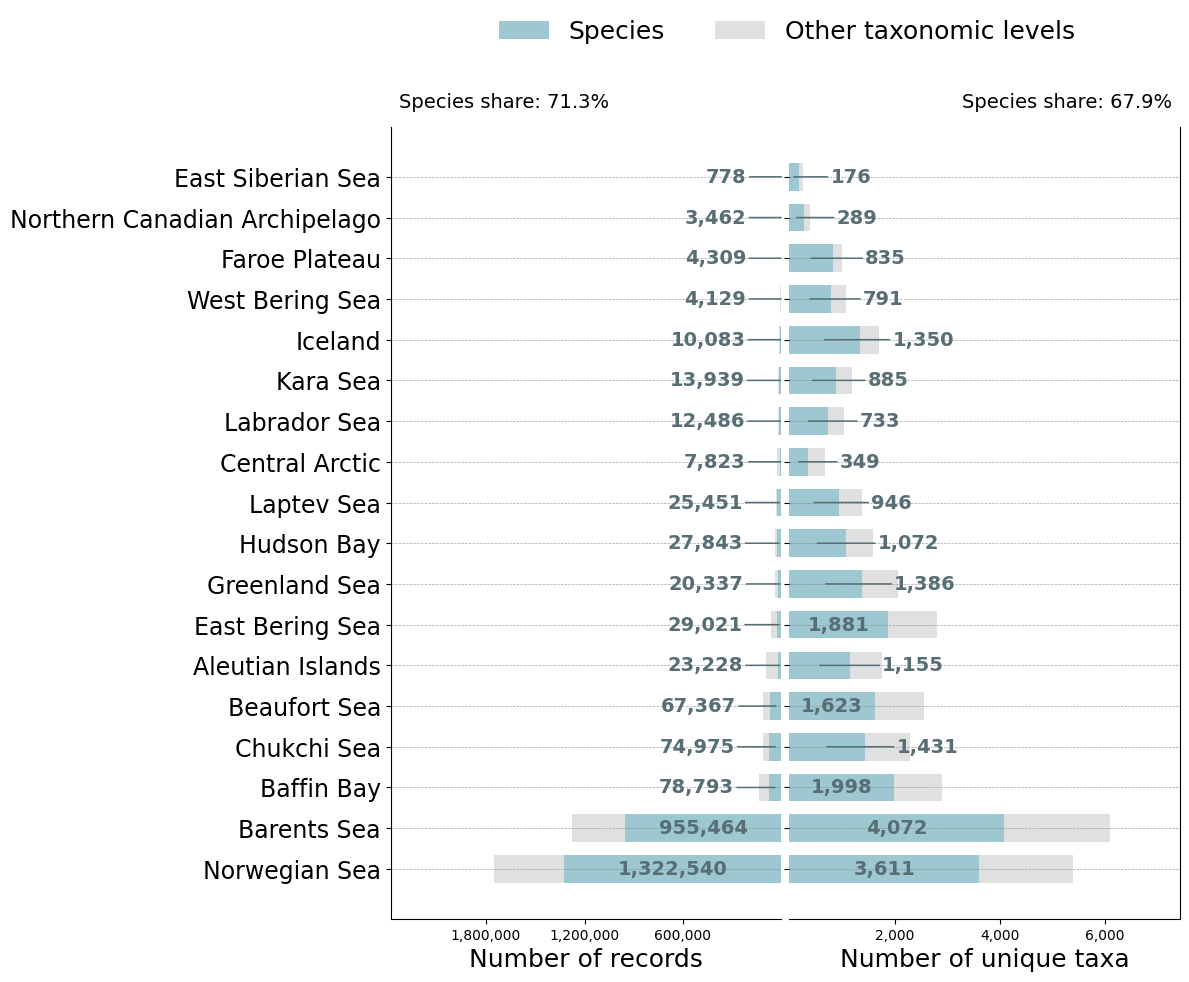

In [44]:
#| fig-pos: "H"
#| label: fig-lme
#| fig-cap: "Number of records (left side) and taxa (right side) of benthic invertebrates in the BENTH-MARC database per Arctic Large Marine Ecosystem. The proportion of species-level data is indicated in teal and by numbers in the bar plot, while grey indicates data on other taxonomic levels. "

# Load data
df_main = pd.read_parquet('Final/merged_all_final.parquet')

# Standardize columns and required fields
df_main.columns = [c.strip() for c in df_main.columns]
lme_col = 'largeMarineEcosystem'
accepted_col = 'acceptedAphiaID'
rank_col = 'taxonRank'

required_cols = [lme_col, accepted_col, rank_col]
missing = [c for c in required_cols if c not in df_main.columns]
if missing:
    raise KeyError(f"Required column(s) missing: {missing}")

# Clean key fields
df_main[accepted_col] = pd.to_numeric(df_main[accepted_col], errors='coerce')
df_main[lme_col] = df_main[lme_col].fillna('Outside Arctic LME coverage')
df_main[lme_col] = df_main[lme_col].astype(str).str.replace(r'\s*LME\s*$', '', regex=True)
rank_norm = df_main[rank_col].astype(str).str.strip().str.upper()

# Records split by species vs other ranks per LME
total_records = df_main.groupby(lme_col, dropna=False).size().reset_index(name='records_total')
species_records = (
    df_main.loc[rank_norm.eq('SPECIES')]
          .groupby(lme_col, dropna=False)
          .size()
          .reset_index(name='records_species')
)
records = pd.merge(total_records, species_records, on=lme_col, how='left').fillna({'records_species': 0})
records['records_species'] = records['records_species'].astype(int)
records['records_other'] = records['records_total'] - records['records_species']

# Unique AphiaID split using any-species appearance within each LME
flags = (
    df_main.dropna(subset=[accepted_col])
          .assign(_is_species=rank_norm.eq('SPECIES'))
          .groupby([lme_col, accepted_col], dropna=False)['_is_species']
          .any()
          .reset_index(name='is_species')
)

unique_total = (
    flags.groupby(lme_col, dropna=False)[accepted_col]
         .nunique()
         .reset_index(name='unique_total')
)
unique_species = (
    flags.loc[flags['is_species']]
         .groupby(lme_col, dropna=False)[accepted_col]
         .nunique()
         .reset_index(name='unique_species')
)

unique_ids = pd.merge(unique_total, unique_species, on=lme_col, how='left').fillna({'unique_species': 0})
unique_ids['unique_species'] = unique_ids['unique_species'].astype(int)
unique_ids['unique_other'] = unique_ids['unique_total'] - unique_ids['unique_species']

# Merge all metrics
metrics = pd.merge(
    records[[lme_col, 'records_total', 'records_species', 'records_other']],
    unique_ids[[lme_col, 'unique_total', 'unique_species', 'unique_other']],
    on=lme_col,
    how='outer'
).fillna(0)

for c in ['records_total', 'records_species', 'records_other', 'unique_total', 'unique_species', 'unique_other']:
    metrics[c] = metrics[c].astype(int)

# Sort LMEs by total records
order_all_lmes = metrics.sort_values('records_total', ascending=False)[lme_col].tolist()
plot_df = metrics.set_index(lme_col).loc[order_all_lmes].reset_index()

# Colors
species_color = '#9DC8D2'
other_color = '#E0E0E0'
species_label_color = mcolors.to_hex(np.array(mcolors.to_rgb(species_color)) * 0.55)

# Overall species shares
records_species_pct_lme = 100 * plot_df['records_species'].sum() / max(plot_df['records_total'].sum(), 1)
unique_species_pct_lme = 100 * plot_df['unique_species'].sum() / max(plot_df['unique_total'].sum(), 1)

# Build mirrored stacked plot
fig, (ax_left, ax_right) = plt.subplots(
    ncols=2,
    figsize=(12, max(6, int(len(order_all_lmes) * 0.56))),
    gridspec_kw={'width_ratios': [1, 1]}
 )

y = np.arange(len(plot_df))

# Left: records (negative)
ax_left.barh(y, -plot_df['records_species'], color=species_color, label='Species', height=0.68)
ax_left.barh(y, -plot_df['records_other'], left=-plot_df['records_species'], color=other_color, label='Other ranks', height=0.68)

# Right: unique taxa (positive)
ax_right.barh(y, plot_df['unique_species'], color=species_color, label='Species', height=0.68)
ax_right.barh(y, plot_df['unique_other'], left=plot_df['unique_species'], color=other_color, label='Other ranks', height=0.68)

left_max = float(plot_df['records_total'].max())
right_max = float(plot_df['unique_total'].max())

# Axes styling
ax_left.set_xlabel('Number of records', fontsize=18)
ax_left.set_xlim(-left_max * 1.36, 0)
ax_left.spines['right'].set_visible(False)
ax_left.spines['top'].set_visible(False)
ax_left.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(abs(x)):,}'))
ax_left.xaxis.set_major_locator(MaxNLocator(nbins=4, prune='both'))

ax_right.set_xlabel('Number of unique taxa', fontsize=18)
ax_right.set_xlim(0, right_max * 1.22)
ax_right.spines['left'].set_visible(False)
ax_right.spines['top'].set_visible(False)
ax_right.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(x):,}'))
ax_right.xaxis.set_major_locator(MaxNLocator(nbins=4, prune='both'))

# Gridlines
ax_left.grid(axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
ax_right.grid(axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7)

# Y labels
ax_left.set_yticks(y)
ax_left.set_yticklabels(order_all_lmes, fontsize=17)
ax_right.set_yticks(y)
ax_right.set_yticklabels([])

# Draw to get renderer for fit checks
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

def text_fits_segment(ax, text, x_center, y_center, seg_width, pad_px=8, fontsize=17, fontweight='bold'):
    tmp = ax.text(x_center, y_center, text, fontsize=fontsize, fontweight=fontweight, alpha=0.0)
    bb = tmp.get_window_extent(renderer=renderer)
    tmp.remove()

    x0 = ax.transData.transform((x_center - seg_width / 2.0, y_center))[0]
    x1 = ax.transData.transform((x_center + seg_width / 2.0, y_center))[0]
    seg_px = abs(x1 - x0)
    return bb.width <= max(0, seg_px - pad_px)

left_outside_offset = left_max * 0.12
right_outside_offset = right_max * 0.10

# Species labels only: inside if fit, otherwise outside with connector lines
for i, row in plot_df.iterrows():
    rec_species = int(row['records_species'])
    uniq_species = int(row['unique_species'])

    rec_species_str = f"{rec_species:,}"
    uniq_species_str = f"{uniq_species:,}"

    rec_species_center = -rec_species / 2.0
    uniq_species_center = uniq_species / 2.0

    if rec_species > 0 and text_fits_segment(ax_left, rec_species_str, rec_species_center, y[i], rec_species):
        ax_left.text(
            rec_species_center, y[i], rec_species_str,
            ha='center', va='center', fontsize=14,
            color=species_label_color, fontweight='bold'
        )
    else:
        rec_label_x = -rec_species - left_outside_offset
        ax_left.annotate(
            rec_species_str,
            xy=(rec_species_center, y[i]),
            xytext=(rec_label_x, y[i]),
            ha='right', va='center',
            fontsize=14, color=species_label_color, fontweight='bold',
            arrowprops=dict(arrowstyle='-', color=species_label_color, lw=1.1, shrinkA=0, shrinkB=0)
        )

    if uniq_species > 0 and text_fits_segment(ax_right, uniq_species_str, uniq_species_center, y[i], uniq_species):
        ax_right.text(
            uniq_species_center, y[i], uniq_species_str,
            ha='center', va='center', fontsize=14,
            color=species_label_color, fontweight='bold'
        )
    else:
        uniq_label_x = uniq_species + right_outside_offset
        ax_right.annotate(
            uniq_species_str,
            xy=(uniq_species_center, y[i]),
            xytext=(uniq_label_x, y[i]),
            ha='left', va='center',
            fontsize=14, color=species_label_color, fontweight='bold',
            arrowprops=dict(arrowstyle='-', color=species_label_color, lw=1.1, shrinkA=0, shrinkB=0)
        )

# Species share annotations
ax_left.text(
    0.02, 1.02,
    f"Species share: {records_species_pct_lme:.1f}%",
    transform=ax_left.transAxes,
    fontsize=14,
    ha='left',
    va='bottom'
 )
ax_right.text(
    0.98, 1.02,
    f"Species share: {unique_species_pct_lme:.1f}%",
    transform=ax_right.transAxes,
    fontsize=14,
    ha='right',
    va='bottom'
 )

# Shared legend
legend_handles = [
    Patch(facecolor=species_color, edgecolor='none', label='Species'),
    Patch(facecolor=other_color, edgecolor='none', label='Other taxonomic levels')
]
fig.legend(
    handles=legend_handles,
    loc='upper center',
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.66, 0.99),
    fontsize=18
)

# Layout and save
plt.tight_layout()
plt.subplots_adjust(top=0.86, wspace=0.02)
plt.savefig('Figures/lme_records_taxa_all.png', dpi=220, bbox_inches='tight')
plt.show()

In [45]:
# Calculate percentages of records on shelves, in abyss/hadal, and outside geomorphological categories

df_geo = pd.read_parquet('Final/merged_all_final.parquet')

# Ensure 'geomorphologicalCategory' column exists
if 'geomorphologicalCategory' not in df_geo.columns:
    raise KeyError("The column 'geomorphologicalCategory' is missing from the dataset.")

# Normalize category text to avoid mismatches from spacing/case and naming variants
df_geo['geomorphologicalCategory_clean'] = df_geo['geomorphologicalCategory'].astype(str).str.strip()

# Define shelf categories and flag rows that are on shelves
shelf_levels = {'Shallow shelf', 'Medium shelf', 'Deep shelf'}
df_geo['is_shelf'] = df_geo['geomorphologicalCategory_clean'].isin(shelf_levels)

# Flag abyssal/hadal records using exact names plus robust keyword matching
abyss_levels = {
    'Abyssal plains',
    'Abyssal mountains',
    'Abyssal hills',
    'Hadal',
    'Abyssal mountains and hills',
    'Abyssal plains and hadal zones',
}
df_geo['is_abyssal'] = (
    df_geo['geomorphologicalCategory_clean'].isin(abyss_levels)
    | df_geo['geomorphologicalCategory_clean'].str.contains(r'abyssal|hadal', case=False, na=False)
)

# Compute counts and percentages
total_count_geo = int(len(df_geo))

shelf_count = int(df_geo['is_shelf'].sum())
shelf_pct = (shelf_count / total_count_geo) * 100 if total_count_geo > 0 else float('nan')

abyssal_count = int(df_geo['is_abyssal'].sum())
abyssal_pct = (abyssal_count / total_count_geo) * 100 if total_count_geo > 0 else float('nan')

# Outside geomorphological categories = missing/blank placeholder category entries
outside_missing_tokens = {'', 'nan', 'none', '<na>', 'na'}
outside_mask = df_geo['geomorphologicalCategory'].isna() | df_geo['geomorphologicalCategory_clean'].str.lower().isin(outside_missing_tokens)
outside_count = int(outside_mask.sum())
outside_pct = (outside_count / total_count_geo) * 100 if total_count_geo > 0 else float('nan')

formatted_percentage_shelf_pct = f"{shelf_pct:.0f}"
formatted_percentage_abyssal_pct = f"{abyssal_pct:.0f}"
formatted_percentage_outside_pct = f"{outside_pct:.0f}"

In [46]:
#| include: false

# Load the dataset
df_geo = pd.read_parquet('Final/merged_all_final.parquet')

# Define the taxon column
taxon_col = 'acceptedScientificName'
if taxon_col not in df_geo.columns:
    possible = [c for c in df_geo.columns if 'ScientificName' in c]
    taxon_col = possible[0] if len(possible) > 0 else df_geo.columns[-1]

# Clean and normalize the geomorphology category
df_geo['geomorphologicalCategory_clean'] = df_geo['geomorphologicalCategory'].astype(str).str.strip()

# Group by category and compute summary statistics
grp = df_geo.groupby('geomorphologicalCategory_clean', dropna=False)
summary = grp.agg(
    records=('geomorphologicalCategory_clean', 'size'),
    unique_taxa=(taxon_col, pd.Series.nunique),
).reset_index()

# Compute total records and unique taxa (same basis as before)
total_records_geo = int(summary['records'].sum())
total_unique_taxa = int(summary['unique_taxa'].sum())

# Compute proportions
summary['prop_records'] = summary['records'] / total_records_geo
summary['prop_unique_taxa'] = summary['unique_taxa'] / total_unique_taxa

# Safe inverses (avoid division by zero)
prop_records_safe = summary['prop_records'].replace(0, np.nan)
prop_unique_safe = summary['prop_unique_taxa'].replace(0, np.nan)

# Compute ratios
summary['records_to_taxa_ratio'] = prop_records_safe / prop_unique_safe
summary['taxa_to_records_ratio'] = prop_unique_safe / prop_records_safe

# Deep shelf ratio from exact category
deep_mask = summary['geomorphologicalCategory_clean'].eq('Deep shelf')
deep_shelf_ratio = summary.loc[deep_mask, 'taxa_to_records_ratio'].iloc[0] if deep_mask.any() else None

# Abyssal plains and hadal zones ratio from exact category
abyss_mask = summary['geomorphologicalCategory_clean'].eq('Abyssal plains and hadal zones')
abyssal_plains_hadal_ratio = summary.loc[abyss_mask, 'taxa_to_records_ratio'].iloc[0] if abyss_mask.any() else None

# Backward-compatible aliases used elsewhere in the notebook
shallow_shelf_ratio = deep_shelf_ratio
abyssal_plains_ratio = abyssal_plains_hadal_ratio

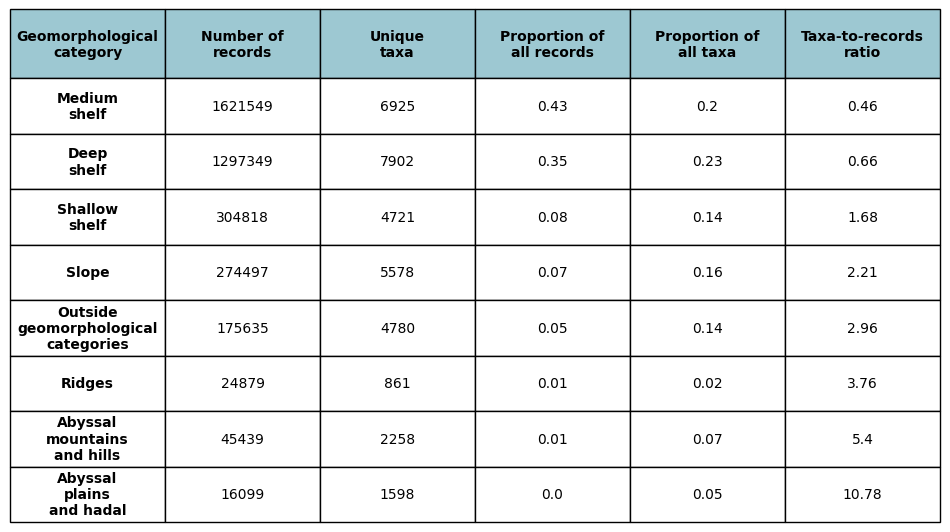

In [47]:
#| include: false

# Load the dataset
try:
    df_geo
except NameError:
    df_geo = pd.read_parquet('Final/merged_all_final.parquet')  # Load if not already in memory
# Pick the taxa column
taxon_col = 'acceptedScientificName'
if taxon_col not in df_geo.columns:
    # Find potential candidates for the taxon column
    candidates = [c for c in df_geo.columns if 'ScientificName' in c]
    taxon_col = candidates[0] if len(candidates) > 0 else df_geo.columns[-1]
# Clean category text (same robust logic as Cell 55)
df_geo['geomorphologicalCategory'] = df_geo['geomorphologicalCategory'].fillna('Outside geomorphological categories')
df_geo['geomorphologicalCategory'] = df_geo['geomorphologicalCategory'].replace('', 'Outside geomorphological categories')
df_geo['geomorphologicalCategory'] = df_geo['geomorphologicalCategory'].astype(str).str.strip()
df_geo.loc[df_geo['geomorphologicalCategory'].isin(['nan', 'None']), 'geomorphologicalCategory'] = 'Outside geomorphological categories'
# Aggregate data
grp = df_geo.groupby('geomorphologicalCategory', dropna=False)
summary_table = grp.agg(
    records=('geomorphologicalCategory', 'size'),
    unique_taxa=(taxon_col, pd.Series.nunique)
).reset_index()
# Compute proportions and ratios
summary_table['prop_records'] = summary_table['records'] / summary_table['records'].sum()
summary_table['prop_unique_taxa'] = summary_table['unique_taxa'] / summary_table['unique_taxa'].sum()
summary_table['taxa_to_records_ratio'] = summary_table['prop_unique_taxa'] / summary_table['prop_records']
# Limit decimals for numeric columns
summary_table['prop_records'] = summary_table['prop_records'].round(2)
summary_table['prop_unique_taxa'] = summary_table['prop_unique_taxa'].round(2)
summary_table['taxa_to_records_ratio'] = summary_table['taxa_to_records_ratio'].round(2)
# Rename columns with row breaks for better formatting
summary_table = summary_table.rename(columns={
    'geomorphologicalCategory': 'Geomorphological\ncategory',
    'records': 'Number of\nrecords',
    'unique_taxa': 'Unique\ntaxa',
    'prop_records': 'Proportion of\nall records',
    'prop_unique_taxa': 'Proportion of\nall taxa',
    'taxa_to_records_ratio': 'Taxa-to-records\nratio'
})
# Add row breaks to category names for better formatting
summary_table['Geomorphological\ncategory'] = summary_table['Geomorphological\ncategory'].replace({
    'Shallow shelf': 'Shallow\nshelf',
    'Medium shelf': 'Medium\nshelf',
    'Deep shelf': 'Deep\nshelf',
    'Abyssal plains and hadal': 'Abyssal\nplains\nand\nhadal',
    'Abyssal plains and hadal zones': 'Abyssal\nplains\nand hadal',
    'Abyssal mountains and hills': 'Abyssal\nmountains\nand hills',
    'Outside geomorphological categories': 'Outside\ngeomorphological\ncategories'
})
# Sort the table by proportion of records
summary_table = summary_table.sort_values('Taxa-to-records\nratio', ascending=True)
# Create a styled table as a plot
fig, ax = plt.subplots(figsize=(12, 6))  # Adjust figure size to fit the table
ax.axis('tight')
ax.axis('off')
# Create the table
table = ax.table(
    cellText=summary_table.values,
    colLabels=summary_table.columns,
    cellLoc='center',
    loc='center'
)
# Style the table
table.auto_set_font_size(False)
table.set_fontsize(10)
# Adjust column widths and row heights
for key, cell in table.get_celld().items():
    cell.set_text_props(ha='center', va='center')  # Center-align text
    if key[0] == 0:  # Header row
        cell.set_fontsize(10)
        cell.set_text_props(weight='bold')  # Bold header text
        cell.set_facecolor('#9DC8D2')  # Set header background color
        cell.set_height(0.15)  # Adjust header row height
    else:
        cell.set_height(0.12)  # Adjust row height for data rows
        if key[1] == 0:  # Geomorphological category column
            cell.set_text_props(weight='bold')  # Make category names bold
# Show the table
plt.show()

Similarly, sampling effort and the availability of records varies considerably over geomorphological features on a pan-Arctic scale. In @fig-geo, the global geomorphological features mapped by Harris *et al.* [@harris2014] have been merged into a coarser set of categories to visualize the distribution of sampling effort in terms of number of records as well as the number of taxa per category. The deep and medium shelves are considerably more well-sampled than other areas (@fig-geo), reflecting the high sampling effort in Barents Sea and the Norwegian Sea that could also be seen in @fig-lme. The Norwegian Sea and Barents Sea are bordered by innumerous fjords and the Barents Sea has numerous troughs that are deep enough to be categorized as medium and deep shelf. 

In [49]:
display(Markdown(
    f"The shelves are most easily accessible and the deep, medium and shallow shelf have together received a staggering {formatted_percentage_shelf_pct}% of the overall sampling effort in terms of number of records sampled. "
    f"At the other end of the spectrum, the hadal zones together with abyssal plains, mountains and hills have collectively only received {formatted_percentage_abyssal_pct}% of the total sampling effort. Due to near-shore " 
    f"locations that fall outside the coverage of the shapefiles provided by Harris *et al.* [@harris2014], {formatted_percentage_outside_pct}% of the records are " 
    f"categorized as Outside geomorphological categories."
))

The shelves are most easily accessible and the deep, medium and shallow shelf have together received a staggering 86% of the overall sampling effort in terms of number of records sampled. At the other end of the spectrum, the hadal zones together with abyssal plains, mountains and hills have collectively only received 2% of the total sampling effort. Due to near-shore locations that fall outside the coverage of the shapefiles provided by Harris *et al.* [@harris2014], 5% of the records are categorized as Outside geomorphological categories.

In [52]:
display(Markdown(
    f"The proportional relationship between the number of records and the number of taxa (i.e. the taxa-to-records ratio) changes with sampling pressure and depth. Wherever the ratio is one to one, the category contributes taxa " 
    f"in line with its share of records. At lower ratios, the category contributes fewer unique taxa than would be expected. The lowest taxa-to-records ratio is found at the deep shelf ({deep_shelf_ratio:.1f}), " 
    f"and the ratio generally gradually increases as the number of records decreases and the depth increases, " 
    f"with abyssal plains and hadal zones having the highest ratio at {abyssal_plains_hadal_ratio:.1f}. There are a few exceptions to the depth-related pattern, " 
    f"such as the shallow and medium shelf having fewer records and a higher ratio than the deep shelf, and ridges having fewer records and a lower ratio than the abyssal mountains and hills. "
    f"The deeper areas are generally less well-sampled and each sample has few individuals, meaning that each sample from these areas has a higher probability of encountering taxa that had not been previously recorded in the area. " 
    f"The ratios indicate that the low numbers of unique taxa in the deep areas are a consequence of low sampling effort rather than a true representation " 
    f"of the actual biodiversity in these areas, and that the deep areas are likely to be considerably more taxon-rich than current data suggest. "
))

The proportional relationship between the number of records and the number of taxa (i.e. the taxa-to-records ratio) changes with sampling pressure and depth. Wherever the ratio is one to one, the category contributes taxa in line with its share of records. At lower ratios, the category contributes fewer unique taxa than would be expected. The lowest taxa-to-records ratio is found at the deep shelf (0.7), and the ratio generally gradually increases as the number of records decreases and the depth increases, with abyssal plains and hadal zones having the highest ratio at 10.8. There are a few exceptions to the depth-related pattern, such as the shallow and medium shelf having fewer records and a higher ratio than the deep shelf, and ridges having fewer records and a lower ratio than the abyssal mountains and hills. The deeper areas are generally less well-sampled and each sample has few individuals, meaning that each sample from these areas has a higher probability of encountering taxa that had not been previously recorded in the area. The ratios indicate that the low numbers of unique taxa in the deep areas are a consequence of low sampling effort rather than a true representation of the actual biodiversity in these areas, and that the deep areas are likely to be considerably more taxon-rich than current data suggest. 

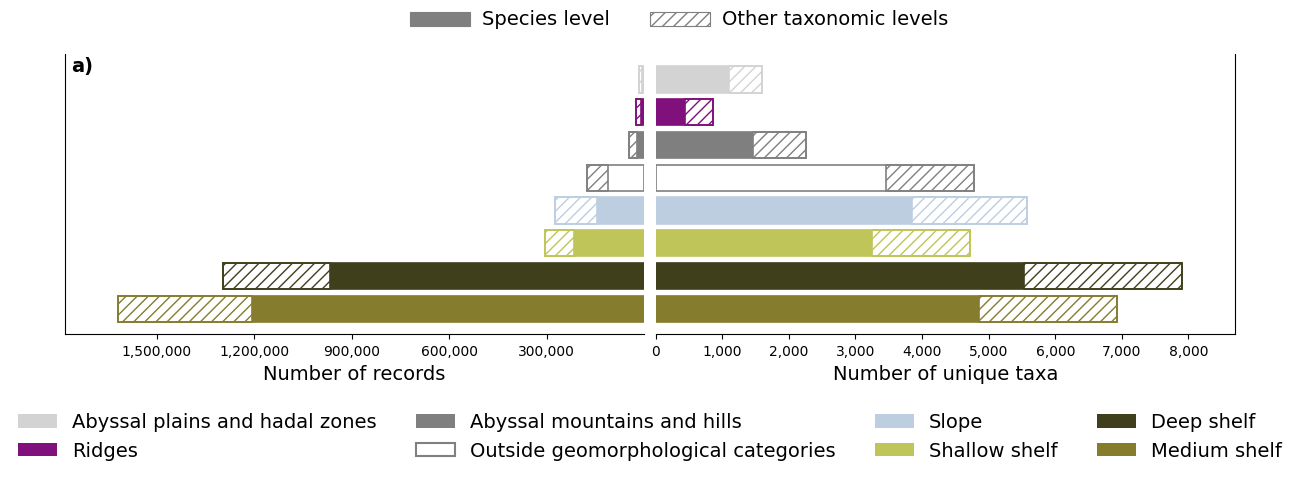

In [30]:
#| fig-pos: "H"

# Load the Excel file
geo_path = 'Final/merged_all_final.parquet'
biota_geo_df = pd.read_parquet(geo_path)

# Clean column names and handle missing values
biota_geo_df.columns = [c.strip() for c in biota_geo_df.columns]  # Strip whitespace from column names
geo_col = 'geomorphologicalCategory'
accepted_col = 'acceptedAphiaID'
rank_col = 'taxonRank'

# Ensure required columns exist
required_cols = [geo_col, accepted_col, rank_col]
missing = [c for c in required_cols if c not in biota_geo_df.columns]
if missing:
    raise KeyError(f"Required column(s) missing: {missing}")

# Convert key columns and clean category labels
biota_geo_df[accepted_col] = pd.to_numeric(biota_geo_df[accepted_col], errors='coerce')
biota_geo_df[geo_col] = biota_geo_df[geo_col].fillna('Outside geomorphological categories')
biota_geo_df[geo_col] = biota_geo_df[geo_col].replace('', 'Outside geomorphological categories')
biota_geo_df[geo_col] = biota_geo_df[geo_col].astype(str).str.strip()
biota_geo_df.loc[biota_geo_df[geo_col].isin(['nan', 'None']), geo_col] = 'Outside geomorphological categories'
rank_norm = biota_geo_df[rank_col].astype(str).str.strip().str.upper()

# Records split by species vs other ranks per geomorphological category
total_records = biota_geo_df.groupby(geo_col, dropna=False).size().reset_index(name='total_records')
species_records = (
    biota_geo_df.loc[rank_norm.eq('SPECIES')]
               .groupby(geo_col, dropna=False)
               .size()
               .reset_index(name='records_species')
)
records = pd.merge(total_records, species_records, on=geo_col, how='left').fillna({'records_species': 0})
records['records_species'] = records['records_species'].astype(int)
records['records_other'] = records['total_records'] - records['records_species']

# Unique AphiaID split by any-species appearance within each category
flags = (
    biota_geo_df.dropna(subset=[accepted_col])
               .assign(_is_species=rank_norm.eq('SPECIES'))
               .groupby([geo_col, accepted_col], dropna=False)['_is_species']
               .any()
               .reset_index(name='is_species')
)
unique_total = (
    flags.groupby(geo_col, dropna=False)[accepted_col]
         .nunique()
         .reset_index(name='unique_taxa')
)
unique_species = (
    flags.loc[flags['is_species']]
         .groupby(geo_col, dropna=False)[accepted_col]
         .nunique()
         .reset_index(name='unique_species')
)
unique_ids = pd.merge(unique_total, unique_species, on=geo_col, how='left').fillna({'unique_species': 0})
unique_ids['unique_species'] = unique_ids['unique_species'].astype(int)
unique_ids['unique_other'] = unique_ids['unique_taxa'] - unique_ids['unique_species']

# Merge metrics into a single DataFrame
summary_df = pd.merge(
    records[[geo_col, 'total_records', 'records_species', 'records_other']],
    unique_ids[[geo_col, 'unique_taxa', 'unique_species', 'unique_other']],
    on=geo_col,
    how='outer'
).fillna(0)
for c in ['total_records', 'records_species', 'records_other', 'unique_taxa', 'unique_species', 'unique_other']:
    summary_df[c] = summary_df[c].astype(int)

# Sort data so that categories with the highest number of records are lowest on the y-axis
summary_df = summary_df.sort_values('total_records', ascending=False)

# Define colors for each category
category_colors = {
    'Abyssal plains': '#C3C3C3',
    'Ridges': '#80107B',
    'Abyssal mountains and hills': '#7F7F7F',
    'Slope': '#BDCEE1',
    'Deep shelf': '#403F1B',
    'Medium shelf': '#857C2E',
    'Shallow shelf': '#BFC558',
    'Outside geomorphological categories': 'white'
}

# Prepare data for plotting
categories = summary_df[geo_col].tolist()
species_colors = [category_colors.get(cat, 'lightgray') for cat in categories]
other_colors = ['white' for _ in categories]
edge_colors = [
    'gray' if cat == 'Outside geomorphological categories' else category_colors.get(cat, 'lightgray')
    for cat in categories
]

# Create mirrored bar plot
fig, (ax_left, ax_right) = plt.subplots(
    ncols=2, figsize=(12, 4), gridspec_kw={'width_ratios': [1, 1]}
)

# Left: records (negative)
ax_left.barh(
    categories,
    -summary_df['records_species'],
    color=species_colors,
    edgecolor='none',
    linewidth=1.0
 )
ax_left.barh(
    categories,
    -summary_df['records_other'],
    left=-summary_df['records_species'],
    color=other_colors,
    edgecolor=edge_colors,
    hatch='///',
    linewidth=1.2
 )
# Outline the full stacked bars
ax_left.barh(
    categories,
    -summary_df['total_records'],
    color='none',
    edgecolor=edge_colors,
    linewidth=1.2
 )

# Right: unique taxa (positive)
ax_right.barh(
    categories,
    summary_df['unique_species'],
    color=species_colors,
    edgecolor='none',
    linewidth=1.0
 )
ax_right.barh(
    categories,
    summary_df['unique_other'],
    left=summary_df['unique_species'],
    color=other_colors,
    edgecolor=edge_colors,
    hatch='///',
    linewidth=1.2
 )
# Outline the full stacked bars
ax_right.barh(
    categories,
    summary_df['unique_taxa'],
    color='none',
    edgecolor=edge_colors,
    linewidth=1.2
 )

# Format axes
ax_left.set_xlabel('Number of records', fontsize=14)
ax_left.set_xlim(-summary_df['total_records'].max() * 1.1, 0)
ax_left.spines['right'].set_visible(False)
ax_left.spines['top'].set_visible(False)
ax_left.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(abs(x)):,}'))  # Thousands separator
ax_left.xaxis.set_major_locator(MaxNLocator(nbins=7, prune='both'))

ax_right.set_xlabel('Number of unique taxa', fontsize=14)
ax_right.set_xlim(0, summary_df['unique_taxa'].max() * 1.1)
ax_right.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(abs(x)):,}'))  # Thousands separator
ax_right.spines['left'].set_visible(False)
ax_right.spines['top'].set_visible(False)

# Remove y-ticks and labels
ax_left.set_yticks([])
ax_left.set_yticklabels([])
ax_right.set_yticks([])
ax_right.set_yticklabels([])
ax_left.text(0.01, 0.99, 'a)', transform=ax_left.transAxes, ha='left', va='top', fontsize=14, fontweight='bold', zorder=10)

# Add style legend for taxonomic level (top) with text outside sample boxes
box_w, box_h = 0.05, 0.035
y_box = 0.965
x_species = 0.3
x_other = 0.5

species_box = plt.Rectangle(
    (x_species, y_box - box_h), box_w, box_h,
    transform=fig.transFigure,
    facecolor='#7F7F7F',
    edgecolor='#7F7F7F',
    linewidth=0.8,
    clip_on=False
)
other_box = plt.Rectangle(
    (x_other, y_box - box_h), box_w, box_h,
    transform=fig.transFigure,
    facecolor='white',
    edgecolor='#7F7F7F',
    hatch='///',
    linewidth=0.8,
    clip_on=False
)
fig.add_artist(species_box)
fig.add_artist(other_box)

fig.text(
    x_species + box_w + 0.01, y_box - box_h / 2, 'Species level',
    ha='left', va='center', fontsize=14, color='black'
)
fig.text(
    x_other + box_w + 0.01, y_box - box_h / 2, 'Other taxonomic levels',
    ha='left', va='center', fontsize=14, color='black'
)

# Keep category legend below the plot
legend_categories = categories[::-1]
legend_labels = [f"{cat}" for cat in legend_categories]
legend_patches = [
    Patch(
        facecolor=category_colors.get(cat, 'lightgray'),
        edgecolor='gray' if cat == 'Outside geomorphological categories' else 'none',
        linewidth=1.5
    )
    for cat in legend_categories
]
fig.legend(
    legend_patches,
    legend_labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.20),
    ncol=4,
    fontsize=14,
    frameon=False,
    markerscale=3
)

# Adjust layout and save the plot
plt.tight_layout()
plt.subplots_adjust(top=0.86, wspace=0.02)
plt.savefig('Figures/geo_records_taxa.png', dpi=220, bbox_inches='tight')
plt.show()

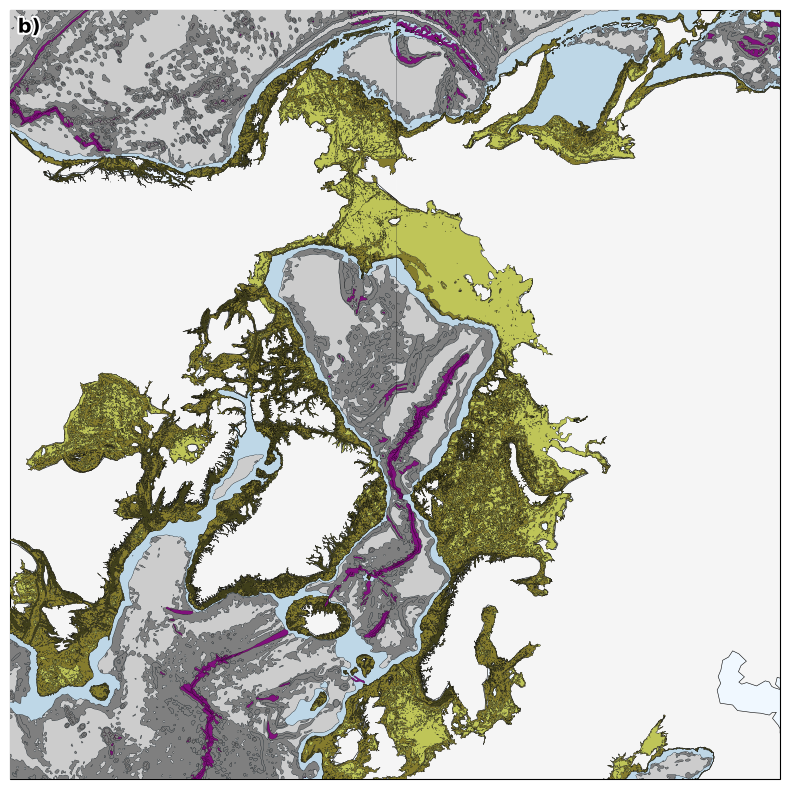

In [25]:
#| fig-pos: "H"
#| label: fig-geo
#| fig-cap: "a) Number of records and taxa of benthic invertebrates in the BENTH-MARC database per geomorphological category. Figure 6: b) A visual representation of the geomorphological categories, simplified from Harris *et al.* [@harris2014]. "

# ------------------------------------------ Map ------------------------------------------------

# Cell 1 — Imports and config

# Folder containing your shapefiles
geo_dir = 'Geo'
# List of shapefile filenames to load from ./Geo (add more as needed)
layer_files = [
    'Hadal.shp',
    'Abyss.shp',
    'Slope.shp',
    'Shelf.shp',
    'Abyssal_Classification.shp',
    'Shelf_Classification.shp',
    'Spreading_ridges.shp',
    'Ridges.shp',
    'Rift_valleys.shp',
    'Seamounts.shp'
]

# Cell 2 — Load shapefiles from ./Geo
layers = {}
for fname in layer_files:
    fpath = os.path.join(geo_dir, fname)
    if os.path.exists(fpath):
        gdf_loaded = gpd.read_file(fpath)
        key_name = os.path.splitext(fname)[0]
        layers[key_name] = gdf_loaded

# Cell 3 — Configure class colors (RGBA) and defaults
abyssal_class_field = 'Class'  # Update this if your column name differs
abyssal_class_colors = {
    'Hills': (0.498, 0.498, 0.498, 1.0),  # fixed
    'Mountains': (0.498, 0.498, 0.498, 1.0),  # fixed
    'Plains': (0.8, 0.8, 0.8, 1.0)   # fixed
}
shelf_class_field = 'Class'  # Update this if your column name differs
shelf_class_colors = {
    'high': (0.251, 0.247, 0.106, 1.0),  # Light blue
    'medium': (0.522, 0.486, 0.180, 1.0),  # Green
    'low': (0.749, 0.773, 0.345, 1.0)   # Orange
}
layer_colors_rgba = {
    'Hadal': (0.8, 0.8, 0.8, 1.0),  # Dark blue, previously (0.129, 0.443, 0.710, 1.0)
    'Abyss': (0.420, 0.682, 0.843, 1.0),  # Light blue
    'Ridges': (0.502, 0.063, 0.482, 1.0),  # Purple
    'Slope': (0.745, 0.843, 0.906, 1.0),  # Purple
    'Shelf': (0.933, 0.953, 1.0, 1.0),  # Purple
    'Spreading_ridges': (0.502, 0.063, 0.482, 1.0),  # Purple
    'Rift_valleys': (0.502, 0.063, 0.482, 1.0),  # Purple
    'Seamounts': (0.498, 0.498, 0.498, 1.0)  # Purple
}
default_color = (0.5, 0.5, 0.5, 0.5)  # Gray with transparency

# Simplify geometries for faster plotting
simp_tol_deg = 0.02
simplified_layers = {}
for lname, gdf in layers.items():
    sgdf = gdf.copy()
    sgdf['geometry'] = sgdf.geometry.simplify(simp_tol_deg, preserve_topology=True)
    simplified_layers[lname] = sgdf

# Cell 4 — Plot preview (rasterized)
fig = plt.figure(figsize=(8, 8))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='whitesmoke', zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue', zorder=0)
ax.coastlines(resolution='110m', linewidth=0.4, color='black', zorder=2)
legend_handles = []
# Define zorder for each layer explicitly
layer_zorder = {
    'Hadal': 3,
    'Abyss': 4,
    'Abyssal_Classification': 5,
    'Shelf_Classification': 8,
    'Slope': 7,
    'Shelf': 6,
    'Spreading_ridges': 9,
    'Ridges': 10,
    'Rift_valleys': 11,
    'Seamounts': 12
}
# Plot layers in the specified order with explicit zorder
for fname in layer_files:
    lname = os.path.splitext(fname)[0]  # Get layer name without extension
    if lname in simplified_layers:
        gdf = simplified_layers[lname]
        rgba = layer_colors_rgba.get(lname, default_color)
        geoms = [geom for geom in gdf.geometry if geom is not None]
        if len(geoms) > 0:
            artist = ax.add_geometries(
                geoms,
                crs=ccrs.PlateCarree(),
                facecolor=rgba,
                edgecolor='k',
                linewidth=0.15,
                alpha=rgba[3],
                zorder=layer_zorder[lname]  # Use explicit zorder
            )
            legend_handles.append(Patch(facecolor=rgba, edgecolor='k', label=lname))
# Plot Abyssal_Classification with class-specific colors
if 'Abyssal_Classification' in simplified_layers:
    gdfc = simplified_layers['Abyssal_Classification']
    for cls_name, cls_rgba in abyssal_class_colors.items():
        subset = gdfc[gdfc[abyssal_class_field].astype(str) == cls_name]
        geoms = [geom for geom in subset.geometry if geom is not None]
        if len(geoms) > 0:
            artist = ax.add_geometries(
                geoms,
                crs=ccrs.PlateCarree(),
                facecolor=cls_rgba,
                edgecolor='k',
                linewidth=0.12,
                alpha=cls_rgba[3],
                zorder=layer_zorder['Abyssal_Classification']  # Explicit zorder for Abyssal_Classification
            )
            legend_handles.append(Patch(facecolor=cls_rgba, edgecolor='k', label='Abyssal ' + cls_name))
ax.text(0.01, 0.99, 'b)', transform=ax.transAxes, ha='left', va='top',
        fontsize=14, fontweight='bold', color='black',
        path_effects=[pe.withStroke(linewidth=3, foreground='white')], zorder=20)
# Plot Shelf_Classification with class-specific colors
if 'Shelf_Classification' in simplified_layers:
    gdfc = simplified_layers['Shelf_Classification']
    for cls_name, cls_rgba in shelf_class_colors.items():
        subset = gdfc[gdfc[shelf_class_field].astype(str) == cls_name]
        geoms = [geom for geom in subset.geometry if geom is not None]
        if len(geoms) > 0:
            artist = ax.add_geometries(
                geoms,
                crs=ccrs.PlateCarree(),
                facecolor=cls_rgba,
                edgecolor='k',
                linewidth=0.12,
                alpha=cls_rgba[3],
                zorder=layer_zorder['Shelf_Classification']  # Explicit zorder for Shelf_Classification
            )

plt.tight_layout()
out_path = 'Figures/geo_map.png'
plt.savefig(out_path, dpi=300)
plt.show()


In [53]:
# | include: false
# # Calculate depth statistics from gebcoDepth column
df_depth = pd.read_parquet('Final/merged_all_final.parquet', columns=['gebcoDepth'])

# Remove NaN values and get absolute depth (convert to positive)
depth_valid = df_depth['gebcoDepth'].dropna().abs()

# Calculate median depth
median_depth_m = depth_valid.median()

# Calculate percentage deeper than 300 meters
pct_over_300 = (depth_valid > 300).sum() / len(depth_valid) * 100

# Calculate percentage in top 1000 meters (0-1000m)
pct_in_0_1000 = (depth_valid <= 1000).sum() / len(depth_valid) * 100

print(f"Median depth: {median_depth_m:.0f} meters")
print(f"Percentage deeper than 300 meters: {pct_over_300:.1f}%")
print(f"Percentage in top 1000 meters: {pct_in_0_1000:.1f}%")

Median depth: 265 meters
Percentage deeper than 300 meters: 38.8%
Percentage in top 1000 meters: 96.9%


In [54]:
display(Markdown(
    f"Visualizing the distribution of records over depth provides an even clearer picture of the decreasing sampling effort with depth. The vast majority of sampling has occurred at shallow depths (@fig-depth), " 
    f"with 50% of the records being sampled at a depth of less than {median_depth_m:.0f} meters, and only {pct_over_300:.0f}% being sampled at a "
    f"depth greater than 300 meters. Approximately {pct_in_0_1000:.0f}% of the records come from sampling conducted in the top 1000 meters. Due to incomplete coverage in the depth column, extracted depth values from "
    f"GEBCO's gridded bathymetry data [@gebco2025] were used in the graph. " 
))

Visualizing the distribution of records over depth provides an even clearer picture of the decreasing sampling effort with depth. The vast majority of sampling has occurred at shallow depths (@fig-depth), with 50% of the records being sampled at a depth of less than 265 meters, and only 39% being sampled at a depth greater than 300 meters. Approximately 97% of the records come from sampling conducted in the top 1000 meters. Due to incomplete coverage in the depth column, extracted depth values from GEBCO's gridded bathymetry data [@gebco2025] were used in the graph. 

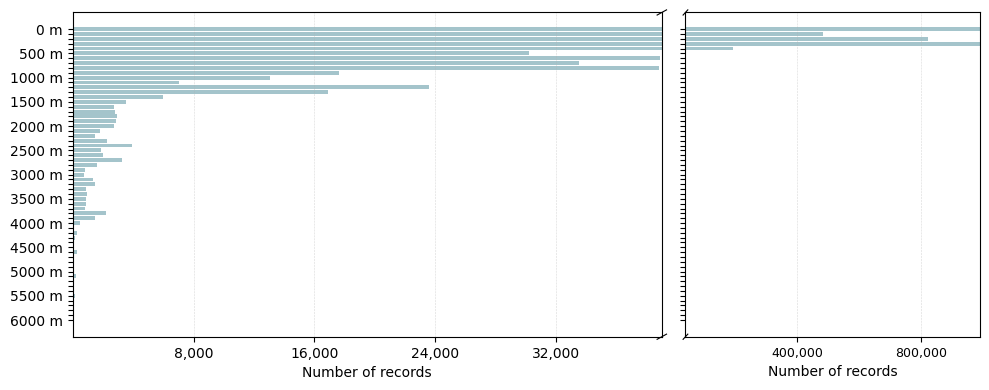

In [55]:
#| fig-pos: "H"
#| label: fig-depth
#| fig-cap: "Number of records of benthic invertebrates over depth range in the BENTH-MARC database. Note the different scales in the split x axis."


# Load data
df_depth = pd.read_parquet('Final/merged_all_final.parquet')
bathy_abs = df_depth['gebcoDepth'].dropna().abs()
# Build 100 m bins across full observed range
bin_width = 100
max_depth_full = int(np.ceil(bathy_abs.max() / bin_width) * bin_width)
edges_full = np.arange(0, max_depth_full + bin_width, bin_width)
labels_full = [str(i) + ' to ' + str(i + bin_width) + ' m' for i in range(0, max_depth_full, bin_width)]
binned_full = pd.cut(bathy_abs, bins=edges_full, right=True, include_lowest=True, labels=labels_full)
counts_full = binned_full.value_counts(sort=False).reset_index()
counts_full.columns = ['bin_label', 'records']
counts_full['bin_start'] = counts_full['bin_label'].apply(lambda s: int(str(s).split(' to ')[0]))
counts_full = counts_full.sort_values('bin_start').reset_index(drop=True)
# Filter bins to exclude depths greater than 6000 meters
counts_full = counts_full[counts_full['bin_start'] <= 6000].reset_index(drop=True)
# Create y-tick positions and labels
ytick_positions = np.arange(len(counts_full))
ytick_labels = []
for _, row in counts_full.iterrows():
    start_val = int(str(row['bin_label']).split(' to ')[0].replace(' m', ''))
    if start_val % 500 == 0:
        ytick_labels.append(str(start_val) + ' m')
    else:
        ytick_labels.append('')
# Build the two-panel broken x-axis barplot with data-driven x-axis break
max_records = float(counts_full['records'].max())
p90_records = float(counts_full['records'].quantile(0.90))
x_break = int(np.ceil(p90_records / 500.0) * 500)
x_break = max(1000, min(x_break, int(np.floor(max_records * 0.85))))
if x_break <= 0:
    x_break = 1000
right_mask = counts_full['records'] > x_break
if not right_mask.any():
    x_break = int(max(500, np.floor(max_records * 0.8)))
    right_mask = counts_full['records'] > x_break
right_xlim_max = int(np.ceil(max_records / 500.0) * 500) if max_records > 0 else x_break + 500
fig, (ax1, ax2) = plt.subplots(ncols=2, sharey=True, figsize=(10, 4), gridspec_kw={'width_ratios': [2, 1]})
# Left panel (0..x_break)
sns.barplot(data=counts_full, y='bin_label', x='records', color='#9DC8D2', orient='h', errorbar=None, ax=ax1)
ax1.set_xlim(0, x_break)
# Right panel (>x_break)
sns.barplot(data=counts_full[right_mask], y='bin_label', x='records', color='#9DC8D2', orient='h', errorbar=None, ax=ax2)
ax2.set_xlim(x_break, right_xlim_max)
# Apply y ticks/labels to both panels
ax1.set_yticks(ytick_positions)
ax1.set_yticklabels(ytick_labels)
ax2.set_yticks(ytick_positions)
ax2.set_yticklabels(ytick_labels)
# Format x-axis ticks for readability
ax1.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True, prune='both'))
ax1.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(x):,}'))
ax2.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True, prune='both'))
ax2.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(x):,}'))
ax2.tick_params(axis='x', labelsize=9)
# Diagonal break markers
d = 0.008
kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False, linewidth=0.8)
ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)
ax1.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)
kwargs.update(transform=ax2.transAxes)
ax2.plot((-d, +d), (-d, +d), **kwargs)
ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)
# Style
for ax in (ax1, ax2):
    ax.set_xlabel('Number of records')
    ax.set_ylabel('')
    ax.grid(axis='x', linestyle='--', linewidth=0.4, alpha=0.5, zorder=0)
plt.tight_layout()
out_path = 'Figures/depth.png'
plt.savefig(out_path, dpi=300)
plt.show()

In [56]:
# | include: false
# Calculate percentage of records from 1700s and before 2000

source_df = pd.read_parquet('Final/merged_all_final.parquet')

df_year = source_df[['year']].copy()
df_year['year'] = pd.to_numeric(df_year['year'], errors='coerce')

# Remove NaN years
df_year_valid = df_year.dropna()

total_records_year = len(df_year_valid)

# Records from 1600s (1600-1699)
records_1600s = ((df_year_valid['year'] >= 1600) & (df_year_valid['year'] < 1700)).sum()
pct_1600s = (records_1600s / total_records_year * 100) if total_records_year > 0 else 0.0

# Records from 1700s (1700-1799)
records_1700s = ((df_year_valid['year'] >= 1700) & (df_year_valid['year'] < 1800)).sum()
pct_1700s = (records_1700s / total_records_year * 100) if total_records_year > 0 else 0.0

# Records from 1800s (1800-1899)
records_1800s = ((df_year_valid['year'] >= 1800) & (df_year_valid['year'] < 1900)).sum()
pct_1800s_valid = (records_1800s / total_records_year * 100) if total_records_year > 0 else 0.0

# Records before 2000 (year < 2000)
records_before_2000 = (df_year_valid['year'] < 2000).sum()
pct_before_2000_valid = (records_before_2000 / total_records_year * 100) if total_records_year > 0 else 0.0

print(f"Percentage from 1600s: {pct_1600s:.10f}%")
print(f"Percentage from 1700s: {pct_1700s:.10f}%")
print(f"Percentage from 1800s: {pct_1800s_valid:.1f}%")
print(f"Percentage before 2000: {pct_before_2000_valid:.1f}%")

Percentage from 1600s: 0.0000000000%
Percentage from 1700s: 0.0007620103%
Percentage from 1800s: 0.9%
Percentage before 2000: 15.0%


In [57]:
display(Markdown(
    f"The data in BENTH-MARC span back all the way to the 1700s, but only {(pct_1800s_valid + pct_1700s + pct_1600s):.0f}% of the records originate from before the 20th century (@fig-time). "
    f"The vast majority of the data are recent, with {100-pct_before_2000_valid:.0f}% of the records being sampled after year 2000. "
    f"Apart from the increasing number of records over time, there also appears to have been a shift in focus from sampling only one or a few taxonomic groups at a time to "
    f"more community-oriented sampling. @fig-time a) shows the development over time from almost exclusively single-phylum stations to a clear downward trend in single-phylum stations since around year 2000. " 
    f"The relative increase over the previous three years might be related to a time lag in the identification of taxa in more comprehensive, community-based studies. " 
    f"The overall reduction in single-phylum stations can be interpreted as a shift in research focus from taxonomy to ecology. "
    f"Together, the limited availability of historic data and the shift in study focus limit the applicability of the data in long-term comparisons. "
    f"There are however examples of long-term comparisons in the literature that have successfully used publicly available data to compare species distributions over time, such as Calvin et al. 2024 [@calvet2024]. "
))

The data in BENTH-MARC span back all the way to the 1700s, but only 1% of the records originate from before the 20th century (@fig-time). The vast majority of the data are recent, with 85% of the records being sampled after year 2000. Apart from the increasing number of records over time, there also appears to have been a shift in focus from sampling only one or a few taxonomic groups at a time to more community-oriented sampling. @fig-time a) shows the development over time from almost exclusively single-phylum stations to a clear downward trend in single-phylum stations since around year 2000. The relative increase over the previous three years might be related to a time lag in the identification of taxa in more comprehensive, community-based studies. The overall reduction in single-phylum stations can be interpreted as a shift in research focus from taxonomy to ecology. Together, the limited availability of historic data and the shift in study focus limit the applicability of the data in long-term comparisons. There are however examples of long-term comparisons in the literature that have successfully used publicly available data to compare species distributions over time, such as Calvin et al. 2024 [@calvet2024]. 

@fig-time b) shows the six most common phyla among single-phylum stations, in decreasing order of number of sample stations. Cnidaria, Porifera, Arthropoda, Mollusca and Echinodermata have been the focus at more than 10,000 stations each, whereas Annelida has been the focus of fewer targeted studies. 

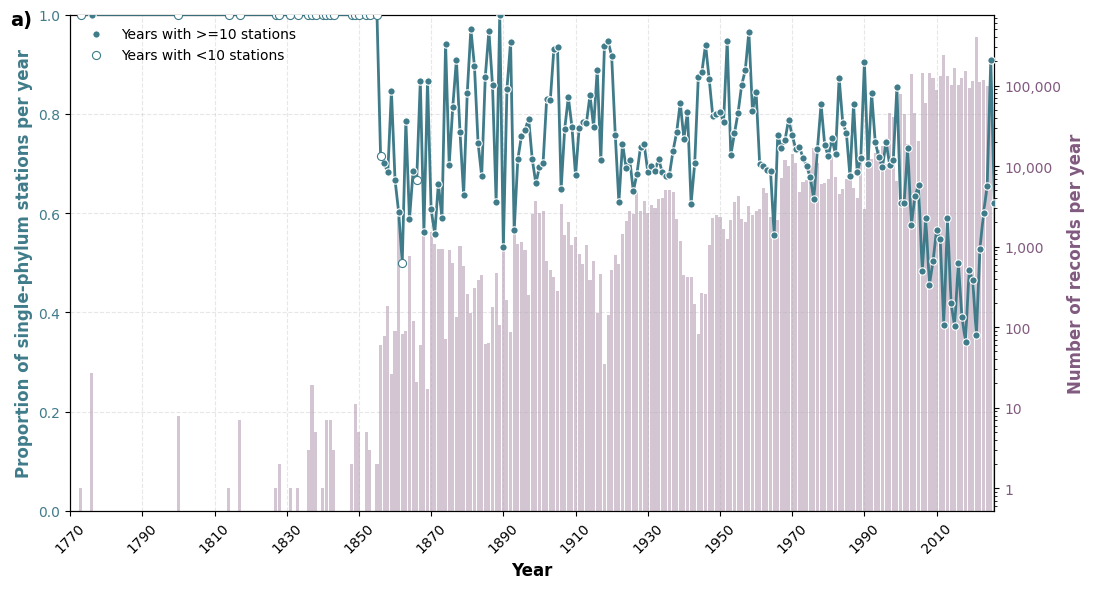

In [19]:
# Plot dual-axis chart using all_merged.parquet and all_stations.parquet
# Shows: records per year + proportion of single-phylum stations per year
#| fig-pos: "H"

# Load source data
all_merged_df = pd.read_parquet('Final/merged_all_final.parquet')
all_stations_df = pd.read_parquet('Final/all_stations.parquet')

# Shared station-defining columns available in both parquet files
station_cols = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart', 'year']
required_merged = station_cols + ['phylum']
missing_merged = [c for c in required_merged if c not in all_merged_df.columns]
missing_stations = [c for c in station_cols if c not in all_stations_df.columns]
if missing_merged:
    raise KeyError(f"Missing required column(s) in all_merged.parquet: {missing_merged}")
if missing_stations:
    raise KeyError(f"Missing required column(s) in all_stations.parquet: {missing_stations}")

# Prepare station universe from all_stations (denominator)
stations = all_stations_df[station_cols].copy()
stations['year'] = pd.to_numeric(stations['year'], errors='coerce')
stations['decimalLatitudeStart'] = pd.to_numeric(stations['decimalLatitudeStart'], errors='coerce').round(5)
stations['decimalLongitudeStart'] = pd.to_numeric(stations['decimalLongitudeStart'], errors='coerce').round(5)
stations = stations.dropna(subset=station_cols)
stations['year'] = stations['year'].astype(int)
stations = stations.drop_duplicates(station_cols)

# Prepare merged records and normalize phylum
merged = all_merged_df[required_merged].copy()
merged['year'] = pd.to_numeric(merged['year'], errors='coerce')
merged['decimalLatitudeStart'] = pd.to_numeric(merged['decimalLatitudeStart'], errors='coerce').round(5)
merged['decimalLongitudeStart'] = pd.to_numeric(merged['decimalLongitudeStart'], errors='coerce').round(5)
merged = merged.dropna(subset=station_cols)
merged['year'] = merged['year'].astype(int)
merged['phylum_norm'] = merged['phylum'].astype(str).str.strip().str.lower()
merged_valid = merged[~merged['phylum_norm'].isin(['', 'nan', 'none', '<na>'])].copy()

# Records per year (bars)
records_per_year = merged.groupby('year').size().reset_index(name='RecordCount')

# Number of unique phyla per station-year from all_merged
station_phyla = (
    merged_valid.groupby(station_cols, as_index=False)['phylum_norm']
              .nunique()
              .rename(columns={'phylum_norm': 'n_phyla'})
)

# Join to all stations so denominator truly comes from all_stations
station_summary = stations.merge(station_phyla, on=station_cols, how='left')
station_summary['n_phyla'] = station_summary['n_phyla'].fillna(0)

single_per_year = (
    station_summary.groupby('year', as_index=False)
                   .agg(
                       TotalStations=('n_phyla', 'size'),
                       SingleStations=('n_phyla', lambda s: int((s == 1).sum()))
                   )
)
single_per_year['Prop_Single'] = np.where(
    single_per_year['TotalStations'] > 0,
    single_per_year['SingleStations'] / single_per_year['TotalStations'],
    np.nan
)

# Final plotting frame
plot_df_sorted = (
    records_per_year.merge(
        single_per_year[['year', 'TotalStations', 'Prop_Single']],
        on='year',
        how='left'
    )
    .sort_values('year')
    .rename(columns={'year': 'Year'})
)

# Colors per existing style
color_prop = '#3F7B89'
color_prop_low_n = "#FFFFFF"  # marker color for years with <10 stations
color_recs = '#815A7F'

plt.figure(figsize=(11, 6))
ax1 = plt.gca()

# Bars on secondary axis
ax2 = ax1.twinx()
ax2.bar(plot_df_sorted['Year'], plot_df_sorted['RecordCount'], color=color_recs, alpha=0.35, width=0.85, label='Records per year', zorder=1)
ax2.set_ylabel('Number of records per year', color=color_recs, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_recs)
ax2.set_yscale('log')
ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:,.0f}'))

# Ensure line/markers are drawn above bars in twin-axis rendering
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_alpha(0)

# Line on primary axis
sns.lineplot(
    data=plot_df_sorted,
    x='Year',
    y='Prop_Single',
    color=color_prop,
    linewidth=2.0,
    marker=None,
    ax=ax1,
    zorder=5,
    label='_nolegend_'
 )

# Markers with different colors for low station-count years
mask_low_n = plot_df_sorted['TotalStations'] < 10
mask_ok_n = ~mask_low_n

ax1.scatter(
    plot_df_sorted.loc[mask_ok_n, 'Year'],
    plot_df_sorted.loc[mask_ok_n, 'Prop_Single'],
    s=28,
    color=color_prop,
    edgecolor='white',
    linewidth=0.8,
    zorder=6,
    label='Years with >=10 stations'
 )
ax1.scatter(
    plot_df_sorted.loc[mask_low_n, 'Year'],
    plot_df_sorted.loc[mask_low_n, 'Prop_Single'],
    s=34,
    color=color_prop_low_n,
    edgecolor='#3F7B89',
    linewidth=0.8,
    zorder=7,
    label='Years with <10 stations'
 )

# Axes style
ax1.set_ylabel('Proportion of single-phylum stations per year', color=color_prop, fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_prop)
ax1.set_ylim(0, 1)
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.set_xlabel('Year', fontsize=12, fontweight='bold')
ax1.set_title('', fontsize=14, fontweight='bold')

# More x ticks and labels
min_year = int(plot_df_sorted['Year'].min())
max_year = int(plot_df_sorted['Year'].max())
ax1.set_xticks(np.arange(1770, max_year + 1, 20))
ax1.set_xlim(1770, max_year)
ax1.tick_params(axis='x', labelrotation=45)
ax1.text(-0.065, 1.01, 'a)', transform=ax1.transAxes, ha='left', va='top', fontsize=14, fontweight='bold', zorder=10)

# Legend
handles1, labels1 = ax1.get_legend_handles_labels()
ax1.legend(handles1, labels1, loc='upper left', frameon=False, fontsize=10)

plt.tight_layout()

# Save output
fig_path = 'Figures/time.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

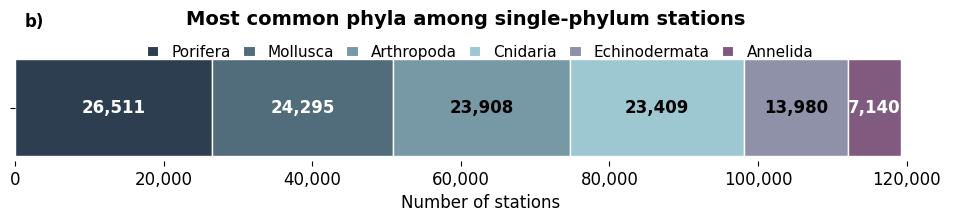

In [27]:
#| label: fig-time
#| fig-cap: "a) The number of records of benthic invertebrates in the BENTH-MARC database over time and the proportion of single-phylum stations per year, indicating a shift in sampling focus from single-phylum stations to communities. Figure 8: b) The phyla that have most commonly been the focus of single-phylum stations."
#| fig-pos: "H"

# Rebase to use parquet files and same station definition as cell 60
# Count single-phylum stations by phylum

# Load source data (reuse from cell 60 if available, or reload)
try:
    all_merged_df
    all_stations_df
except NameError:
    all_merged_df = pd.read_parquet('Final/merged_all_final.parquet')
    all_stations_df = pd.read_parquet('Final/all_stations_final.parquet')

# Same station definition from cell 60
station_cols = ['datasetKey', 'decimalLatitudeStart', 'decimalLongitudeStart', 'year']

# Prepare stations
stations = all_stations_df[station_cols].copy()
stations['year'] = pd.to_numeric(stations['year'], errors='coerce')
stations['decimalLatitudeStart'] = pd.to_numeric(stations['decimalLatitudeStart'], errors='coerce').round(5)
stations['decimalLongitudeStart'] = pd.to_numeric(stations['decimalLongitudeStart'], errors='coerce').round(5)
stations = stations.dropna(subset=station_cols)
stations['year'] = stations['year'].astype(int)
stations = stations.drop_duplicates(station_cols)

# Prepare merged records and normalize phylum
merged = all_merged_df[station_cols + ['phylum']].copy()
merged['year'] = pd.to_numeric(merged['year'], errors='coerce')
merged['decimalLatitudeStart'] = pd.to_numeric(merged['decimalLatitudeStart'], errors='coerce').round(5)
merged['decimalLongitudeStart'] = pd.to_numeric(merged['decimalLongitudeStart'], errors='coerce').round(5)
merged = merged.dropna(subset=station_cols)
merged['year'] = merged['year'].astype(int)
merged['phylum_norm'] = merged['phylum'].astype(str).str.strip().str.lower()
merged_valid = merged[~merged['phylum_norm'].isin(['', 'nan', 'none', '<na>'])].copy()

# Count unique phyla per station
station_phyla = (
    merged_valid.groupby(station_cols, as_index=False)['phylum_norm']
              .nunique()
              .rename(columns={'phylum_norm': 'n_phyla'})
)

# Join to all stations
station_summary = stations.merge(station_phyla, on=station_cols, how='left')
station_summary['n_phyla'] = station_summary['n_phyla'].fillna(0)

# Filter to single-phylum stations only
single_phylum_stations = station_summary[station_summary['n_phyla'] == 1].copy()

# Get the phylum for each single-phylum station
single_stations_with_phyla = single_phylum_stations.merge(
    merged_valid[station_cols + ['phylum_norm']].drop_duplicates(station_cols),
    on=station_cols,
    how='left',
)

# Count stations by phylum, sorted descending
phylum_counts = (
    single_stations_with_phyla.groupby('phylum_norm', as_index=False).size()
    .rename(columns={'size': 'station_count'})
    .sort_values('station_count', ascending=False)
)

# Keep only phyla with enough stations
min_station_count = 4000
plot_df = phylum_counts[phylum_counts['station_count'] > min_station_count].copy()

if plot_df.empty:
    raise ValueError(f'No phyla have more than {min_station_count:,} stations.')

# Prepare for plotting
labels = plot_df['phylum_norm'].tolist()
values = plot_df['station_count'].tolist()

# Build colors dynamically to match whatever phyla pass the threshold
base_colors = ['#2C3E50','#516C7B','#7799A6','#9DC8D2','#8F91A9','#815A7F']
if len(base_colors) < len(values):
    base_colors = base_colors * ((len(values) // len(base_colors)) + 1)
colors = base_colors[:len(values)]

# Cumulative left positions for each segment
cum_left = np.cumsum([0] + list(values[:-1]))

# Plot the bars
plt.figure(figsize=(12, 1.8))
for lab, val, left, color in zip(labels, values, cum_left, colors):
    plt.barh([0], [val], left=left, color=color, edgecolor='white', height=0.08)

    if val > 0:
        x_center = left + val / 2.0
        count = int(val)

        # Calculate luminance to determine text color
        r, g, b = [int(color.lstrip('#')[j:j+2], 16) for j in (0, 2, 4)]
        luminance = 0.2126 * r + 0.7152 * g + 0.0722 * b
        txt_color = 'white' if luminance < 128 else 'black'

        # Add count text with thousand separators
        text_str = f'{count:,}'
        plt.text(
            x_center,
            0,
            text_str,
            va='center',
            ha='center',
            color=txt_color,
            fontsize=12,
            fontweight='bold',
        )

# Create legend only for plotted phyla
from matplotlib.patches import Patch
legend_labels = [lab.capitalize() for lab in labels]
legend_patches = [Patch(facecolor=color, edgecolor='white', linewidth=1.5) for color in colors]

ax = plt.gca()
plt.legend(
    handles=legend_patches,
    labels=legend_labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.22),
    ncol=min(6, len(legend_labels)),
    frameon=False,
    fontsize=11,
    handleheight=0.8,
    handlelength=0.8,
    columnspacing=0.8,
)

plt.suptitle('Most common phyla among single-phylum stations', fontsize=14, fontweight='bold', y=0.95)

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(False)

# Customize plot with thousands formatter on x-axis
plt.yticks([0], [''])
plt.xlabel('Number of stations', fontsize=12)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(x):,}'))
plt.xticks(fontsize=12)
ax.text(0.01, 1.4, 'b)', transform=ax.transAxes, ha='left', va='top', fontsize=12, fontweight='bold', zorder=10)

# Adjust layout and save the figure
plt.subplots_adjust(top=0.7)
fig_path = 'Figures/single_phylum.png'
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()

# Data availability
All data described in this paper can be accessed as Parquet or CSV files on Zenodo website. Usage license is under Creative Commons Attribution 4.0 International (CC-BY-4.0). 

# Code availability
The R and Python code that was used to create the database BENTH-MARC and to generate figures 1-8 can be found in the GitHub repository arctic-benthic-biodiverity [@githubrep]. 

# Author contributions
The first authorship is shared between H.M. and J.S., who performed the majority of the data curation. In addition, J.D. also contributed with data curation. M.S., C.P., C.G., L.T.D.C., and P.A. contributed with unpublished datasets. H.M., B.B., J.D., P.R., R.P., and M.S. developed the conceptual design of the paper. H.M. wrote the manuscript draft and all other authors contributed with manuscript revisions. 

# Competing interests
No competing interests are declared for this work.

# Funding
This work was funded by the Horizon Europe project POMP - Polar Ocean Mitigation Potential (grant agreement 101136875). The POMP project has been approved under HORIZON-CL6-2023-CLIMATE-01-3: Ocean and coastal waters carbon- and biodiversity-rich ecosystems and habitats in Europe and the Polar Regions.

# References